# ADFL replication (clean, reproducible) + attack screen - multi-dataset

Replicates **ADFL** (Zhu et al., *Computers & Security* 2023): a GAN + knowledge-distillation backdoor defense for federated learning. The pipeline is **dataset-parametrized** (`Config.DATASET`):

| `DATASET` | Model | Attacks replicated (paper-faithful) |
|---|---|---|
| `mnist` | small CNN (paper Table 1), 28x28x1 | 5x5 pixel block -> label 1 |
| `fashion_mnist` | same CNN / GAN as MNIST | 5x5 pixel block + "1" watermark blend (factor `WM_FACTOR`) -> label 1 |
| `cifar10` | CIFAR ResNet18 (3x3 stem, no maxpool; `CIFAR_MODEL="cnn"` is a lighter fallback), 32x32x3 | attribute/semantic backdoor (green-dominant automobiles -> airplane, no added pixels) + 5x5 pixel block -> airplane |

For each dataset x attack the notebook trains a backdoored FL model, applies ADFL (model-seeded GAN + KD from a small clean teacher) and reports ASR/ACC before vs after; then it runs the OOD / "Path-B" evasion screen and full-FL-confirms the best survivors. Each run writes `results_{DATASET}.json`; the final **Comparison** section aggregates every `results_*.json` found in `WORK_DIR` into one table.

**Running on Kaggle**
1. Enable a **GPU accelerator** (Settings -> Accelerator). Turn **Internet on** (torchvision downloads the dataset) or attach the dataset.
2. **One dataset per session:** set `Config.DATASET` and Run All. Every expensive stage (backdoored FL model per attack, clean teacher, GAN, distillation data) writes a **dataset-namespaced** checkpoint to `/kaggle/working` (`backdoored_{DATASET}_{ATTACK}.pt`, `clean_{DATASET}.pt`, `generator_{DATASET}.pt`, `distill_{DATASET}.pt`) and is **skipped on re-run** if it exists (set `FORCE_RETRAIN = True` to recompute). Runs for different datasets therefore never clobber each other.
3. Files in `/kaggle/working` survive closing the browser tab while the session is alive. To persist them after the session dies, use **Save Version** (commit) so they become notebook output. To compare datasets run in separate sessions, copy each session's `results_{DATASET}.json` into the session that runs the Comparison section (or attach the earlier versions' output as input data and copy the JSON files into `WORK_DIR`).
4. **Resuming after a browser reopen or kernel restart:** run the definition cells (everything down to and including the *RESUME* cell) - `reload_all()` repopulates all variables from the checkpoints in seconds, with no retraining.

**Scope (Phase A + multi-dataset):** the GAN is faithful to the paper's Algorithm 1 - its discriminator is seeded from the backdoored global model (see section 13). Old un-namespaced checkpoints (`backdoored_model.pt`, `generator.pt`, ...) from earlier versions of this notebook are **ignored** (the new names differ), so a stale clean-only GAN can no longer be loaded by accident; rename an old `backdoored_model.pt` / `clean_model.pt` to the new MNIST names if you want to reuse them. Deviations from the paper (FL scale, CIFAR architecture/rounds, the semantic-subset approximation) are listed in the Reproducibility table at the end.

## 1. Environment & seeds

In [1]:
import os, glob, json, pickle, shutil, random
from copy import deepcopy
from dataclasses import dataclass

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

Device: cuda


## 2. Config

In [2]:
# ============================= EXPERIMENT SELECTOR =============================
# Pick a run: set RUN to 1..7 and Run All (or export ADFL_RUN=<n>). Leave RUN = None to use the
# manual values in the Config cell below (original behaviour).
#   1  control   : MNIST          - paper fidelity - IID        - seeds 42,43,44
#   2  headline  : Fashion-MNIST  - paper fidelity - IID        - seeds 42,43,44
#   3  Non-IID   : Fashion-MNIST  - paper fidelity - Dirichlet  - seeds 42,43,44
#   4  CIFAR     : CIFAR-10       - paper fidelity - IID        - seed  42
#   5  Non-IID + ADFL_EXPERIMENT=partition_var        : Fashion-MNIST Dirichlet, seed-varying partition + teacher
#   6  Non-IID + ADFL_EXPERIMENT=teacher_gan_ablation : Fashion-MNIST Dirichlet, 2x2 teacher/GAN IID-vs-Non-IID data
#   7  CIFAR (3 seeds): CIFAR-10 - paper fidelity - IID - seeds 42,43,44
#   8  MNIST Non-IID control: MNIST - paper fidelity - Dirichlet - seeds 42,43,44 (pixel only)
#   9  Adaptive trigger + ADFL_EXPERIMENT=adaptive_trigger  : Fashion-MNIST Dirichlet, ES-optimised trigger vs ADFL (oracle+surrogate)
# One dataset per session: finish a run (or start a fresh runtime) before switching.
RUN = int(os.environ["ADFL_RUN"]) if os.environ.get("ADFL_RUN") else 2
RUN_PRESETS = {
    1: dict(DATASET="mnist",         FIDELITY="paper", PARTITION="iid",       DIRICHLET_ALPHA=0.5, SEEDS=[42, 43, 44]),
    2: dict(DATASET="fashion_mnist", FIDELITY="paper", PARTITION="iid",       DIRICHLET_ALPHA=0.5, SEEDS=[42, 43, 44]),
    3: dict(DATASET="fashion_mnist", FIDELITY="paper", PARTITION="dirichlet", DIRICHLET_ALPHA=0.5, SEEDS=[42, 43, 44]),
    4: dict(DATASET="cifar10",       FIDELITY="paper", PARTITION="iid",       DIRICHLET_ALPHA=0.5, SEEDS=[42]),
    5: dict(DATASET="fashion_mnist", FIDELITY="paper", PARTITION="dirichlet", DIRICHLET_ALPHA=0.5, SEEDS=[42, 43, 44]),
    6: dict(DATASET="fashion_mnist", FIDELITY="paper", PARTITION="dirichlet", DIRICHLET_ALPHA=0.5, SEEDS=[42, 43, 44]),
    7: dict(DATASET="cifar10",       FIDELITY="paper", PARTITION="iid",       DIRICHLET_ALPHA=0.5, SEEDS=[42, 43, 44]),
    8: dict(DATASET="mnist",         FIDELITY="paper", PARTITION="dirichlet", DIRICHLET_ALPHA=0.5, SEEDS=[42, 43, 44]),  # MNIST Non-IID negative control
    9: dict(DATASET="fashion_mnist", FIDELITY="paper", PARTITION="dirichlet", DIRICHLET_ALPHA=0.5, SEEDS=[42, 43, 44]),      # adaptive-trigger attacker (ES-optimised, paper 3-seed)
}
assert RUN in (None, 1, 2, 3, 4, 5, 6, 7, 8, 9), f"RUN must be None or 1..9, got {RUN!r}"
if RUN is not None:
    print(f"[EXPERIMENT SELECTOR] RUN={RUN}: {RUN_PRESETS[RUN]}")
else:
    print("[EXPERIMENT SELECTOR] RUN=None -> using manual Config values below")
EXPERIMENT = os.environ.get("ADFL_EXPERIMENT", "")  # "" | "partition_var" | "teacher_gan_ablation" | "adaptive_trigger"
print(f"[EXPERIMENT SELECTOR] EXPERIMENT={EXPERIMENT!r}")


[EXPERIMENT SELECTOR] RUN=2: {'DATASET': 'fashion_mnist', 'FIDELITY': 'paper', 'PARTITION': 'iid', 'DIRICHLET_ALPHA': 0.5, 'SEEDS': [42]}


In [3]:
class Config:
    # ---- Which experiment this session runs (one dataset per Kaggle session) ----
    DATASET         = "fashion_mnist"     # "mnist" | "fashion_mnist" | "cifar10"
    ATTACKS         = None        # None = every attack registered for the dataset; or a list such as ["pixel"]
    WM_FACTOR       = 0.3         # watermark blend factor (paper: ~0.1/0.3/0.5; its Fig. 6 uses 0.3)
    CIFAR_MODEL     = "resnet18"  # "resnet18" (CIFAR ResNet18, paper-like) | "cnn" (light fallback, ~10x faster per FL round)
    FIDELITY        = "fast"      # "fast" (scaled-down baseline below) | "paper" (FIDELITY_OVERRIDES: paper-scale FL; slow)
    PARTITION       = "iid"       # "iid" | "dirichlet" (Non-IID; the paper also evaluates Non-IID via a Dirichlet split)
    DIRICHLET_ALPHA = 0.5         # Dir(alpha) concentration for PARTITION="dirichlet" (smaller = more skewed)

    # Federated learning (scaled down from the paper; see Reproducibility cell)
    N_CLIENTS       = 20          # paper: 100
    # Paper: "10 participants selected per round, 3 of them malicious" (a per-ROUND count, ~30% of the cohort);
    # it states no malicious fraction of the 100 clients, so we keep 25% of clients malicious and scale it
    # with N_CLIENTS under FIDELITY="paper" (25/100, 12/50).
    N_MALICIOUS     = 5           # 25% malicious
    CLIENTS_PER_RND = 10          # paper: 10
    N_ROUNDS        = 100         # paper: 300
    LOCAL_EPOCHS    = 2           # paper: 20
    LOCAL_LR        = 0.05
    BATCH_SIZE      = 256  # raised from 64: fewer/larger steps for launch-bound FL; numeric deviation absorbed by 3-seed mean+/-std
    ATTACK_SCALE    = 1.5         # model-replacement scaling of malicious updates (OUR value: the paper only says
                                  # attackers replace the model and gives no scale -- a reviewer may ask)

    # Backdoor
    TARGET_LABEL    = 1           # default (paper uses "1"); the active DatasetSpec.target_label overrides it
    POISON_RATE     = 0.5         # fraction of an attacker's data that is poisoned

    # Server-side defense data
    CLEAN_RATIO     = 0.03        # server's clean data (teacher), fraction of train
    CLEAN_EPOCHS    = 40
    GAN_RATIO       = 0.10        # clean data used to train the GAN
    GAN_EPOCHS      = 30
    N_DISTILL       = 10000       # size of the GAN distillation set
    KD_EPOCHS       = 20
    KD_T            = 3.0
    KD_ALPHA        = 0.5
    KD_LR           = 1e-3        # Adam lr of the KD student (CIFAR override lowers it)
    GAN_G_LR        = 2e-4        # GAN generator Adam lr
    GAN_D_LR        = 2e-4        # GAN discriminator Adam lr (CIFAR lowers it: the seeded D is strong)
    GAN_G_STEPS     = 1           # generator updates per discriminator update (TTUR / rebalance)
    GAN_INST_NOISE  = 0.0         # std of decaying instance noise on D inputs (anti-mode-collapse)

    # Attack / evasion section
    QB_EPOCHS       = 8           # centralized proxy-backdoor epochs (screen_trigger)
    QB_N_TRAIN      = None        # None = proxy backdoor trains on the whole train set
    ATTACK_MAX_CANDIDATES = None  # None = screen all candidates
    EVASION_TOPK    = 3           # full-FL-confirm up to this many screen survivors (pinned candidates count)

    # Override precedence (later wins):  base Config values above
    #   -> FIDELITY_OVERRIDES[FIDELITY]  (applied right after cfg = Config(), below)
    #   -> DATASET_OVERRIDES[DATASET]    (applied in the DatasetSpec cell, so the dataset override wins last).
    # FIDELITY="fast" has no overrides, so every value is the baseline. "default" keys apply to the grayscale
    # datasets (mnist / fashion_mnist); a dataset-named entry replaces "default" for that dataset.
    # A key a fidelity tier pins for a dataset is dropped from that dataset's DATASET_OVERRIDES so the chosen
    # tier is honoured (e.g. paper-tier CIFAR N_ROUNDS=100 instead of the fast-tier 60).
    FIDELITY_OVERRIDES = {
        "fast": {},
        "paper": {
            "default": dict(N_CLIENTS=100, N_MALICIOUS=25, CLIENTS_PER_RND=10, N_ROUNDS=200, LOCAL_EPOCHS=20, LOCAL_LR=0.01),
            # CIFAR ResNet18 at full paper fidelity is infeasible in one session -> explicit reduced compute tier.
            # The off-manifold gate (not full-scale FL) carries the CIFAR claim.
            "cifar10": dict(N_CLIENTS=50, N_MALICIOUS=12, CLIENTS_PER_RND=10, N_ROUNDS=100, LOCAL_EPOCHS=10, LOCAL_LR=0.01),
        },
    }

    # Per-dataset overrides applied on top of the values above once the dataset is chosen
    # (documented deviations; edit freely). CIFAR-10 + ResNet18 FL is the expensive part, so it
    # uses fewer rounds, a larger server clean set (a 3% = 1500-image teacher is too weak on CIFAR)
    # and fewer proxy epochs / confirmations.
    DATASET_OVERRIDES = {
        "cifar10": dict(N_ROUNDS=60, CLEAN_RATIO=0.10, QB_EPOCHS=4, EVASION_TOPK=2,
                        CLEAN_EPOCHS=70, GAN_EPOCHS=120, GAN_RATIO=0.20, KD_EPOCHS=8, KD_LR=5e-4,
                        GAN_G_LR=2e-4, GAN_D_LR=5e-5, GAN_G_STEPS=2, GAN_INST_NOISE=0.1),
    }

cfg = Config()
# experiment selector (if set) overrides the manual Config fields above, before fidelity/dataset overrides apply
if ("RUN" in dir()) and (RUN is not None):
    _ps = RUN_PRESETS[RUN]
    cfg.DATASET         = _ps["DATASET"]
    cfg.FIDELITY        = _ps["FIDELITY"]
    cfg.PARTITION       = _ps["PARTITION"]
    cfg.DIRICHLET_ALPHA = _ps["DIRICHLET_ALPHA"]
if os.environ.get("ADFL_FIDELITY"): cfg.FIDELITY = os.environ["ADFL_FIDELITY"]  # smoke-test override
assert cfg.FIDELITY in cfg.FIDELITY_OVERRIDES, f"unknown FIDELITY {cfg.FIDELITY!r}"
_fid = cfg.FIDELITY_OVERRIDES[cfg.FIDELITY]
_fid = _fid.get(cfg.DATASET, _fid.get("default", {}))
for _k, _v in _fid.items():
    setattr(cfg, _k, _v)
if _fid:                          # instance copy: the class-level dict stays untouched
    cfg.DATASET_OVERRIDES = {d: {k: v for k, v in o.items() if not (d == cfg.DATASET and k in _fid)}
                             for d, o in cfg.DATASET_OVERRIDES.items()}
    print(f"[fidelity={cfg.FIDELITY}] " + ", ".join(f"cfg.{k}={v}" for k, v in _fid.items()))
ATTACK_SCALE = cfg.ATTACK_SCALE

# Artifact namespacing by partition: "" for IID (existing checkpoints load unchanged), "_dirichlet<alpha>" otherwise.
# Every checkpoint/results filename builder must append PART_TAG (next to MODEL_TAG).
PART_TAG = "" if cfg.PARTITION == "iid" else f"_{cfg.PARTITION}{cfg.DIRICHLET_ALPHA:g}"

# Checkpoint TIER tag: the EFFECTIVE fidelity tier + partition (resolved above, after RUN / FIDELITY_OVERRIDES).
# It is appended to every checkpoint filename (before the _s{seed} suffix and extension) so that a "fast" and a
# "paper" checkpoint, or an iid and a dirichlet one, for the same dataset/attack/seed can never collide.
# PARTITION "dirichlet" is the future Non-IID value (config + tag only; the partition logic lives elsewhere).
CKPT_TIER = f"{cfg.FIDELITY}_{cfg.PARTITION}"

# ---- Runtime / checkpoint config -------------------------------------------
FORCE_RETRAIN = False             # True = ignore existing checkpoints and recompute every stage
FORCE_REGEN_GAN = False           # True = recompute ONLY the GAN + distillation data (keeps the FL/teacher checkpoints). Checkpoints are now dataset-namespaced, so a stale clean-only generator.pt can no longer be loaded by accident; leave False.
# DataLoader workers. 2 is fine on Kaggle (Linux). On Windows, worker processes
# cannot unpickle notebook-defined classes, so fall back to 0 there.
NUM_WORKERS = 0  # forced 0: worker-spawn overhead dominates tiny in-memory FL shards; numerically identical to 2

WORK_DIR = os.environ.get("ADFL_WORK_DIR") or "/kaggle/working"   # ADFL_WORK_DIR: explicit override (e.g. a smoke-test dir)
if os.environ.get("ADFL_WORK_DIR"):
    os.makedirs(WORK_DIR, exist_ok=True)
elif os.path.isdir("/content/drive/MyDrive"):         # Colab + mounted Drive -> persist across sessions
    WORK_DIR = "/content/drive/MyDrive/adfl_work"; os.makedirs(WORK_DIR, exist_ok=True)
elif not os.path.isdir(WORK_DIR):
    WORK_DIR = "."                # local fallback so the notebook still runs off-Kaggle
DATA_DIR = os.environ.get("ADFL_DATA_DIR") or ("/kaggle/temp/data" if os.path.isdir("/kaggle/temp") else "./data")  # keep downloaded datasets out of saved output
os.makedirs(DATA_DIR, exist_ok=True)

def p(name):
    """Path of an artifact inside WORK_DIR."""
    return os.path.join(WORK_DIR, name)

print(f"DATASET={cfg.DATASET}  FIDELITY={cfg.FIDELITY}  PARTITION={cfg.PARTITION}  WORK_DIR={WORK_DIR}  NUM_WORKERS={NUM_WORKERS}  FORCE_RETRAIN={FORCE_RETRAIN}  FORCE_REGEN_GAN={FORCE_REGEN_GAN}")

[fidelity=paper] cfg.N_CLIENTS=100, cfg.N_MALICIOUS=25, cfg.CLIENTS_PER_RND=10, cfg.N_ROUNDS=200, cfg.LOCAL_EPOCHS=20, cfg.LOCAL_LR=0.01
DATASET=fashion_mnist  FIDELITY=paper  PARTITION=iid  WORK_DIR=/kaggle/working  NUM_WORKERS=2  FORCE_RETRAIN=False  FORCE_REGEN_GAN=False


In [4]:
import os, json, glob, shutil, torch

# Check and stage Kaggle input checkpoints into WORK_DIR.
# Verifies saved model checkpoints (attached as a Kaggle *input* dataset from a previous
# Save Version) can be read, then copies them into WORK_DIR so the notebook's existing
# resume logic (load_or_train / reload_all) reuses them instead of retraining.

def _torch_load_any(fpath):
    """torch.load that tolerates newer torch defaulting to weights_only=True.
    Full-object checkpoints (e.g. the distill dataset) need weights_only=False."""
    try:
        return torch.load(fpath, map_location="cpu", weights_only=True)
    except TypeError:
        # old torch: no weights_only kwarg
        return torch.load(fpath, map_location="cpu")
    except Exception:
        # weights_only=True rejected a pickled object -> retry permissively
        return torch.load(fpath, map_location="cpu", weights_only=False)

if not os.path.isdir("/kaggle/input"):
    print("No /kaggle/input (local run) - skipping checkpoint staging.")
else:
    print("\n" + "=" * 80)
    print("CHECKPOINT STAGING: Kaggle input -> WORK_DIR")
    print("=" * 80)

    files_found = []
    for ext in ("*.pt", "*.pth", "*.pkl", "*.json"):
        files_found.extend(glob.glob(f"/kaggle/input/**/{ext}", recursive=True))

    if not files_found:
        print("No checkpoint files found under /kaggle/input.")
    else:
        results = []
        for fpath in sorted(files_found):
            basename = os.path.basename(fpath)
            try:
                size_mb = os.path.getsize(fpath) / (1024 * 1024)
            except Exception:
                size_mb = 0.0
            readable, note = False, ""
            try:
                if fpath.endswith((".pt", ".pth")):
                    _torch_load_any(fpath); readable = True
                elif fpath.endswith(".pkl"):
                    import pickle
                    with open(fpath, "rb") as f: pickle.load(f)
                    readable = True
                elif fpath.endswith(".json"):
                    with open(fpath, "r") as f: json.load(f)
                    readable = True
            except Exception as e:
                note = f"{type(e).__name__}: {str(e)[:40]}"
            results.append((basename, size_mb, readable, note, fpath))

        print(f"\n{'Basename':<40} {'Size(MB)':>9}  {'Readable':<9} Note")
        print("-" * 80)
        for basename, size_mb, readable, note, _ in results:
            print(f"{basename:<40} {size_mb:>9.2f}  {('YES' if readable else 'NO'):<9} {note}")

        print(f"\nStaging readable checkpoints -> {WORK_DIR}:")
        staged = 0
        for basename, _, readable, _, src in results:
            if not readable:
                continue
            dst = p(basename)
            if os.path.exists(dst):
                print(f"  {basename}: already in WORK_DIR (skip)")
                continue
            try:
                shutil.copy2(src, dst)
                print(f"  {basename}: staged -> {dst}")
                staged += 1
            except Exception as e:
                print(f"  {basename}: copy failed ({type(e).__name__})")

        readable_count = sum(1 for r in results if r[2])
        print(f"\nSummary: {len(results)} found, {readable_count} readable, {staged} staged.")
        print("Keep FORCE_RETRAIN=False / FORCE_REGEN_GAN=False to reuse these checkpoints.")
    print("=" * 80)



CHECKPOINT STAGING: Kaggle input -> WORK_DIR



Basename                                  Size(MB)  Readable  Note
--------------------------------------------------------------------------------
backdoored_fashion_mnist_cross_center_FL_fast_iid.pt      6.30  YES       
backdoored_fashion_mnist_horizontal_stripes_FL_fast_iid.pt      6.30  YES       
backdoored_fashion_mnist_nine_dots_FL_fast_iid.pt      6.30  YES       
backdoored_fashion_mnist_pixel_fast_iid.pt      6.30  YES       
backdoored_fashion_mnist_watermark_fast_iid.pt      6.30  YES       
backdoored_mnist_pixel_paper_iid.pt           6.30  YES       
backdoored_mnist_pixel_paper_iid_s43.pt       6.30  YES       
backdoored_mnist_pixel_paper_iid_s44.pt       6.30  YES       
backdoored_mnist_three_corners_FL_paper_iid.pt      6.30  YES       
clean_fashion_mnist_fast_iid.pt               6.30  YES       
clean_mnist_paper_iid.pt                      6.30  YES       
clean_sweep_fashion_mnist.json                0.00  YES       
distill_fashion_mnist_fast_iid.pt         

## 3. Models (classifier, generator, discriminator)
`Classifier` / `Generator` are the unchanged MNIST (28x28x1) models; Fashion-MNIST reuses them. CIFAR-10 has its own 3-channel classifier and color DCGAN generator. The `Discriminator` is built from the *active dataset's* classifier trunk, so the Phase-A model seeding (`seed_model=backdoored_model`) works for every dataset.

In [5]:
class Classifier(nn.Module):
    """Paper Table 1 trunk: 28x28x1 -> 10 classes (MNIST and Fashion-MNIST)."""
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1),  nn.LeakyReLU(0.1), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.LeakyReLU(0.1), nn.MaxPool2d(2),
            nn.Conv2d(32, 128, 3, padding=1),nn.LeakyReLU(0.1),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128*7*7, 256), nn.LeakyReLU(0.1),
            nn.Linear(256, n_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))


class Generator(nn.Module):
    """DCGAN-style generator: z(100) -> 1x28x28 in raw [0,1] pixel scale."""
    def __init__(self, z_dim=100):
        super().__init__()
        self.proj = nn.Sequential(
            nn.Linear(z_dim, 128*7*7),
            nn.BatchNorm1d(128*7*7),
            nn.ReLU(True),
        )
        self.deconv = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1),   # 7 -> 14
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            nn.ConvTranspose2d(64, 1, 4, stride=2, padding=1),     # 14 -> 28
            nn.Sigmoid(),
        )
    def forward(self, z):
        h = self.proj(z).view(-1, 128, 7, 7)
        return self.deconv(h)


# ---------------- CIFAR-10 (3x32x32) ----------------
class _BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False);      self.bn2 = nn.BatchNorm2d(cout)
        self.short = nn.Sequential()
        if stride != 1 or cin != cout:
            self.short = nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))
    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.short(x))


class CifarResNet18(nn.Module):
    """CIFAR-style ResNet18: 3x3 stem, NO initial maxpool, 4 stages of 2 BasicBlocks
    (64-128-256-512), global average pool. `features` = everything up to and including the
    pooled 512-vector, so the Discriminator can reuse (and be seeded from) it exactly like the
    MNIST trunk. 11M parameters: closest to the paper, but ~10x the FL cost of CifarCNN."""
    def __init__(self, n_classes=10):
        super().__init__()
        def stage(cin, cout, stride):
            return [_BasicBlock(cin, cout, stride), _BasicBlock(cout, cout, 1)]
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, 3, 1, 1, bias=False), nn.BatchNorm2d(64), nn.ReLU(),
            *stage(64, 64, 1), *stage(64, 128, 2), *stage(128, 256, 2), *stage(256, 512, 2),
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
        )
        self.classifier = nn.Linear(512, n_classes)
    def forward(self, x):
        return self.classifier(self.features(x))


class CifarCNN(nn.Module):
    """Lighter fallback (3 conv-BN blocks + MLP head, ~0.6M params). Runtime/accuracy tradeoff:
    roughly an order of magnitude faster per FL round than CifarResNet18 on a Kaggle GPU, at a
    few points lower clean accuracy. Select with Config.CIFAR_MODEL = "cnn"."""
    def __init__(self, n_classes=10):
        super().__init__()
        def blk(cin, cout):
            return [nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(), nn.MaxPool2d(2)]
        self.features = nn.Sequential(*blk(3, 32), *blk(32, 64), *blk(64, 128), nn.Flatten())   # 128*4*4
        self.classifier = nn.Sequential(nn.Linear(128*4*4, 256), nn.ReLU(), nn.Linear(256, n_classes))
    def forward(self, x):
        return self.classifier(self.features(x))


class CifarGenerator(nn.Module):
    """Color DCGAN generator (paper Table 1): z(100) -> 3x32x32 in [-1,1] via Tanh.
    Wider trunk (512 start) + a final 3x3 refine conv for mode coverage. Output is [-1,1];
    the [0,1] raw-pixel pipeline maps it back with (x+1)/2 wherever SPEC.gan_tanh is set."""
    def __init__(self, z_dim=100):
        super().__init__()
        self.proj = nn.Sequential(nn.Linear(z_dim, 512*4*4), nn.BatchNorm1d(512*4*4), nn.ReLU(True))
        self.deconv = nn.Sequential(
            nn.ConvTranspose2d(512, 256, 4, 2, 1), nn.BatchNorm2d(256), nn.ReLU(True),   # 4 -> 8
            nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.ReLU(True),   # 8 -> 16
            nn.ConvTranspose2d(128, 64, 4, 2, 1),  nn.BatchNorm2d(64),  nn.ReLU(True),   # 16 -> 32
            nn.Conv2d(64, 3, 3, 1, 1), nn.Tanh(),                                        # refine -> [-1,1]
        )
    def forward(self, z):
        return self.deconv(self.proj(z).view(-1, 512, 4, 4))


class Discriminator(nn.Module):
    """Paper Alg. 1 discriminator: `D(x) <- G_t`.

    The convolutional trunk IS the active dataset's Classifier trunk (paper Table 1: the
    discriminator shares the classifier's architecture). When `seed_model` (the backdoored
    global model) is given, we deep-copy its `features` submodule weights into this
    discriminator, so D starts out sensitive to the backdoored model's learned features. We copy
    the whole `features` submodule's state rather than matching keys by hand, which is robust to
    key naming. The classification head is dropped and replaced by a FRESH randomly-initialised
    Flatten -> Linear(SPEC.feat_dim, 1) real/fake head (feat_dim = 128*7*7 for the 28x28 CNN).

    Input is a RAW [0,1] image (what G outputs); it is normalised internally with the active
    dataset's mean/std because the seeded trunk was trained on normalised inputs."""
    def __init__(self, seed_model=None):
        super().__init__()
        self.features = SPEC.classifier_factory().features      # same arch as the classifier trunk
        if seed_model is not None:
            self.features.load_state_dict(deepcopy(seed_model.features.state_dict()))
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(SPEC.feat_dim, 1))   # new real/fake head
    def forward(self, x):
        if getattr(SPEC, "gan_tanh", False):
            x = (x + 1.0) / 2.0          # Tanh GAN output [-1,1] -> [0,1] raw-pixel space
        return self.head(self.features(normalize(x)))

## 3b. Dataset registry (`DatasetSpec`) - the active spec drives everything below
Each `DatasetSpec` holds the channels / size / classes / mean / std / target label, the classifier + generator + discriminator **factories**, the torchvision **loader**, and the list of **attack configs** (the first one is the *primary* attack: its backdoored model seeds the GAN). `Config.DATASET` selects the active spec; every later cell reads `SPEC`, `MEAN`/`STD`, `new_classifier()`, etc. Switching dataset needs no other code change.

In [6]:
@dataclass
class DatasetSpec:
    name: str
    channels: int
    size: int                 # square image side
    n_classes: int
    mean: tuple               # per-channel
    std: tuple
    target_label: int         # backdoor target class
    classifier_factory: callable
    gen_factory: callable
    disc_factory: callable    # disc_factory(seed_model=None) -> Discriminator
    loader: callable          # () -> (train_set, test_set), normalised tensors
    feat_dim: int             # size of Flatten(classifier.features(x)); used for the D head
    attack_cfgs: list         # [{name, kind, ...}]; first = primary attack
    clean_lr: float = 0.01    # lr of the server's clean teacher (Adam by default)
    augment: bool = False     # tensor-space crop+flip augmentation for the clean teacher
    clean_optim: str = "adam" # "adam" | "sgd"
    clean_wd: float = 0.0
    clean_momentum: float = 0.9
    clean_sched: bool = False # cosine annealing over CLEAN_EPOCHS
    gan_tanh: bool = False    # GAN generator outputs Tanh [-1,1] (Table 1); else Sigmoid [0,1]
    pinned_evasion: tuple = ()  # evasion candidates that are always full-FL-confirmed
    description: str = ""

def _tfm(mean, std):
    return transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)])

def load_mnist():
    tfm = _tfm((0.1307,), (0.3081,))
    train = datasets.MNIST(DATA_DIR, train=True,  download=True, transform=tfm)
    test  = datasets.MNIST(DATA_DIR, train=False, download=True, transform=tfm)
    return train, test

def load_fashion_mnist():
    tfm = _tfm((0.2860,), (0.3530,))
    train = datasets.FashionMNIST(DATA_DIR, train=True,  download=True, transform=tfm)
    test  = datasets.FashionMNIST(DATA_DIR, train=False, download=True, transform=tfm)
    return train, test

def load_cifar10():
    tfm = _tfm((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
    train = datasets.CIFAR10(DATA_DIR, train=True,  download=True, transform=tfm)
    test  = datasets.CIFAR10(DATA_DIR, train=False, download=True, transform=tfm)
    return train, test


REGISTRY = {}

REGISTRY["mnist"] = DatasetSpec(
    name="mnist", channels=1, size=28, n_classes=10,
    mean=(0.1307,), std=(0.3081,), target_label=1,
    classifier_factory=lambda: Classifier(),
    gen_factory=lambda: Generator(),
    disc_factory=lambda seed_model=None: Discriminator(seed_model),
    loader=load_mnist, feat_dim=128*7*7,
    attack_cfgs=[dict(name="pixel", kind="pixel", block=5, strict=True)],     # paper: 5x5 white block, bottom-right, label 1
    pinned_evasion=("three_corners",),          # the Phase-A full-FL-confirmed candidate
    description="MNIST, 28x28x1, small CNN (paper Table 1)",
)

REGISTRY["fashion_mnist"] = DatasetSpec(
    name="fashion_mnist", channels=1, size=28, n_classes=10,
    mean=(0.2860,), std=(0.3530,), target_label=1,            # label 1 = "Trouser"
    classifier_factory=lambda: Classifier(),                  # SAME architectures as MNIST
    gen_factory=lambda: Generator(),
    disc_factory=lambda seed_model=None: Discriminator(seed_model),
    loader=load_fashion_mnist, feat_dim=128*7*7,
    attack_cfgs=[dict(name="pixel", kind="pixel", block=5),
                 dict(name="watermark", kind="watermark")],   # blend a "1" glyph at cfg.WM_FACTOR
    pinned_evasion=(),
    description="Fashion-MNIST, 28x28x1, same CNN/GAN as MNIST",
)

_cifar_cls = {"resnet18": CifarResNet18, "cnn": CifarCNN}[cfg.CIFAR_MODEL]
REGISTRY["cifar10"] = DatasetSpec(
    name="cifar10", channels=3, size=32, n_classes=10,
    mean=(0.4914, 0.4822, 0.4465), std=(0.2470, 0.2435, 0.2616),
    target_label=0,                                           # 0 = airplane ("green cars" -> aircraft, paper Sec. 1)
    classifier_factory=lambda: _cifar_cls(),
    gen_factory=lambda: CifarGenerator(),
    disc_factory=lambda seed_model=None: Discriminator(seed_model),
    loader=load_cifar10, feat_dim=(512 if cfg.CIFAR_MODEL == "resnet18" else 128*4*4),
    attack_cfgs=[dict(name="semantic", kind="semantic", source_class=1,    # class 1 = automobile
                      green_thr=0.20, margin=0.04),
                 dict(name="pixel", kind="pixel", block=5)],
    augment=True, clean_optim="sgd", clean_lr=0.1, clean_wd=5e-4,   # teacher recipe: SGD+nesterov, cosine, crop/flip aug
    clean_momentum=0.9, clean_sched=True, gan_tanh=True,           # Tanh generator + [-1,1] GAN range (Table 1)
    pinned_evasion=(),
    description=f"CIFAR-10, 3x32x32, {cfg.CIFAR_MODEL}",
)


# ---------------- activate the chosen dataset ----------------
DATASET = cfg.DATASET.lower()
assert DATASET in REGISTRY, f"unknown DATASET {cfg.DATASET!r}; choose one of {list(REGISTRY)}"
SPEC = REGISTRY[DATASET]
cfg.TARGET_LABEL = SPEC.target_label
for _k, _v in getattr(cfg, "DATASET_OVERRIDES", {}).get(DATASET, {}).items():
    setattr(cfg, _k, _v)
    print(f"[{DATASET}] override cfg.{_k} = {_v}")

CHANNELS, SIZE, N_CLASSES = SPEC.channels, SPEC.size, SPEC.n_classes
MEAN = torch.tensor(SPEC.mean, dtype=torch.float32).view(-1, 1, 1)     # [C,1,1]: broadcasts over [C,H,W] and [N,C,H,W]
STD  = torch.tensor(SPEC.std,  dtype=torch.float32).view(-1, 1, 1)

def denormalize(x):
    return x * STD.to(x.device, x.dtype) + MEAN.to(x.device, x.dtype)
def normalize(x):
    return (x - MEAN.to(x.device, x.dtype)) / STD.to(x.device, x.dtype)

def new_classifier():  return SPEC.classifier_factory().to(DEVICE)
def new_generator():   return SPEC.gen_factory().to(DEVICE)
def new_discriminator(seed_model=None): return SPEC.disc_factory(seed_model).to(DEVICE)

print(f"Active dataset: {SPEC.name} - {SPEC.description}  | {CHANNELS}x{SIZE}x{SIZE}, target label {SPEC.target_label}, attacks {[c['name'] for c in SPEC.attack_cfgs]}")

Active dataset: fashion_mnist - Fashion-MNIST, 28x28x1, same CNN/GAN as MNIST  | 1x28x28, target label 1, attacks ['pixel', 'watermark']


## 4. Data loading and IID partition

In [7]:
def iid_partition(dataset, n_clients, seed=SEED):
    """Split indices into n_clients roughly equal IID shards."""
    rng = np.random.RandomState(seed)
    idx = rng.permutation(len(dataset))
    return np.array_split(idx, n_clients)

def _get_labels(dataset):
    """Integer labels of a (possibly wrapped) torchvision-style dataset without iterating when avoidable."""
    for attr in ("targets", "labels"):
        if hasattr(dataset, attr):
            return np.asarray(getattr(dataset, attr)).reshape(-1).astype(int)
    if hasattr(dataset, "dataset") and hasattr(dataset, "indices"):      # torch Subset
        return _get_labels(dataset.dataset)[np.asarray(dataset.indices)]
    return np.array([int(dataset[i][1]) for i in range(len(dataset))])   # fallback: read y by indexing

def dirichlet_partition(dataset, n_clients, alpha, seed=SEED, min_size=10):
    """Non-IID split: for each class, divide its samples among clients with proportions ~ Dir(alpha).
    Smaller alpha = more skewed. Returns n_clients index arrays that cover every index exactly once."""
    rng = np.random.RandomState(seed)
    labels = _get_labels(dataset)
    for _ in range(100):                                  # resample until no client is (almost) empty
        shards = [[] for _ in range(n_clients)]
        for c in np.unique(labels):
            idx = rng.permutation(np.where(labels == c)[0])
            cuts = (np.cumsum(rng.dirichlet(alpha * np.ones(n_clients)))[:-1] * len(idx)).astype(int)
            for s, part in zip(shards, np.split(idx, cuts)): s.extend(part.tolist())
        if min(len(s) for s in shards) >= min_size: break
    return [np.array(rng.permutation(s), dtype=np.int64) for s in shards]

def make_loader(dataset, batch_size, shuffle=True):
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                      num_workers=NUM_WORKERS)

train_set, test_set = SPEC.loader()
if cfg.PARTITION == "dirichlet":
    client_indices = dirichlet_partition(train_set, cfg.N_CLIENTS, cfg.DIRICHLET_ALPHA)
else:
    assert cfg.PARTITION == "iid", f"unknown PARTITION {cfg.PARTITION!r}"
    client_indices = iid_partition(train_set, cfg.N_CLIENTS)
print(f"{SPEC.name} [{cfg.PARTITION}{'' if cfg.PARTITION == 'iid' else f' alpha={cfg.DIRICHLET_ALPHA}'}]: train={len(train_set)} test={len(test_set)}  client 0 has {len(client_indices[0])} samples")

  0%|          | 0.00/26.4M [00:00<?, ?B/s]

  0%|          | 32.8k/26.4M [00:00<01:25, 308kB/s]

  0%|          | 65.5k/26.4M [00:00<01:26, 304kB/s]

  0%|          | 131k/26.4M [00:00<00:59, 440kB/s] 

  1%|          | 229k/26.4M [00:00<00:41, 624kB/s]

  2%|▏         | 459k/26.4M [00:00<00:22, 1.16MB/s]

... (21 outputs left out)

100%|██████████| 4.42M/4.42M [00:00<00:00, 5.02MB/s]

  0%|          | 0.00/5.15k [00:00<?, ?B/s]

100%|██████████| 5.15k/5.15k [00:00<00:00, 9.70MB/s]

fashion_mnist [iid]: train=60000 test=10000  client 0 has 600 samples


## 5. Attack module (pixel block, watermark, semantic) - single canonical API
An `AttackSpec` bundles *how an input is triggered* (`apply`), *which test samples count for ASR* (`asr_mask`) and the target label. Three kinds:
- **pixel** - paint rectangles in raw pixel space (generalised to N channels / the active image size; patch values broadcast across channels).
- **watermark** - `apply_watermark(images, wm, factor)`: blend `(1-factor)*x + factor*wm` in raw pixel space, then renormalize (the paper's "1" watermark with a blend factor).
- **semantic** (CIFAR-10, Bagdasaryan-style attribute backdoor) - **no pixels are added**. A natural-feature subset (green-dominant automobiles) is relabeled to the target during the attackers' local training; ASR is measured on the *held-out test* images of that subset, and reported as **excess over the clean teacher's own rate on the same subset** (confound control: some of those images look like airplanes to a clean model anyway).

In [8]:
# Canonical replication trigger (paper): 5x5 white block, bottom-right (28x28: rows/cols 23..27).
# Patch format: (row, col, height, width, value) with value in RAW pixel space; `value` may be a
# scalar (broadcast over channels) or a per-channel tuple.
def apply_trigger(images, patches):
    """images: normalized tensor [N,C,H,W]. Denormalize -> paint rects in raw pixel space ->
    renormalize. Does not modify the input."""
    t = denormalize(images.clone())
    for (r, c, h, w, v) in patches:
        if not np.isscalar(v):
            v = torch.as_tensor(v, dtype=t.dtype, device=t.device).view(1, -1, 1, 1)
        t[:, :, r:r+h, c:c+w] = v
    return normalize(t)

apply_patches = apply_trigger     # alias used by the attack section

def make_watermark(size, channels):
    """Fixed watermark pattern: a handwritten-style "1" (vertical stroke + short flag) in raw
    [0,1] pixels, shape [C,size,size]. Same glyph for every grayscale dataset."""
    wm = torch.zeros(size, size)
    c0, top, bot = size // 2 - 1, int(0.18 * size), int(0.82 * size)
    wm[top:bot, c0:c0 + 2] = 1.0                                  # stroke
    for k in range(max(3, size // 7)):                            # flag, down-left from the top
        wm[top + k, max(c0 - 1 - k, 0)] = 1.0
        wm[top + k, max(c0 - k, 0)] = 1.0
    return wm.unsqueeze(0).repeat(channels, 1, 1)

def apply_watermark(images, wm, factor):
    """images: normalized [N,C,H,W]. Raw-space blend (1-factor)*x + factor*wm, renormalized."""
    t = denormalize(images.clone())
    t = (1.0 - factor) * t + factor * wm.to(t.device, t.dtype)
    return normalize(t)

def greenness(arr_uint8, margin):
    """Fraction of pixels whose green channel exceeds both red and blue by `margin` (raw [0,1]).
    arr_uint8: [N,H,W,3]. Channel heuristic used to define the 'green car' attribute subset."""
    x = arr_uint8.astype(np.float32) / 255.0
    return ((x[..., 1] - np.maximum(x[..., 0], x[..., 2])) > margin).mean(axis=(1, 2))


@dataclass(eq=False)
class AttackSpec:
    name: str
    kind: str                     # "pixel" | "watermark" | "semantic"
    target: int
    desc: str = ""
    param: float = 0.0            # trigger size (pixel) / blend factor (watermark) / subset size (semantic)
    patches: list = None          # pixel
    wm: torch.Tensor = None       # watermark pattern [C,H,W]
    factor: float = None          # watermark blend factor
    sem_train_idx: np.ndarray = None   # semantic: TRAIN indices of the attribute subset (attacker-owned)
    sem_test_mask: torch.Tensor = None # semantic: bool mask over the TEST set = held-out ASR subset
    ctrl_test_mask: torch.Tensor = None# semantic: non-attribute images of the same source class (specificity control)
    strict_asr: bool = False      # assert ASR>0.9 on the backdoored model (MNIST regression guard)

    def apply(self, x):
        """Triggered version of a batch of normalized images."""
        if self.kind == "pixel":
            return apply_trigger(x, self.patches)
        if self.kind == "watermark":
            return apply_watermark(x, self.wm, self.factor)
        return x                  # semantic: natural attribute, nothing is added to the pixels

    def asr_mask(self, y, offset):
        """Bool mask over a test batch `y` (starting at test index `offset`) of the samples that count for ASR."""
        if self.kind == "semantic":
            return self.sem_test_mask[offset:offset + len(y)]
        return y != self.target


def pixel_attack(name, patches, target=None, strict=False):
    return AttackSpec(name=name, kind="pixel", target=SPEC.target_label if target is None else target,
                      patches=patches, desc=name, param=float(len(patches)), strict_asr=strict)

def build_attack(c):
    """Instantiate an AttackSpec from a DatasetSpec attack config (after the data is loaded)."""
    tgt = c.get("target", SPEC.target_label)
    if c["kind"] == "pixel":
        b = c["block"]
        return AttackSpec(name=c["name"], kind="pixel", target=tgt, strict_asr=c.get("strict", False),
                          patches=[(SIZE - b, SIZE - b, b, b, 1.0)], param=float(b),
                          desc=f"{b}x{b} pixel block, bottom-right")
    if c["kind"] == "watermark":
        return AttackSpec(name=c["name"], kind="watermark", target=tgt, wm=make_watermark(SIZE, CHANNELS),
                          factor=cfg.WM_FACTOR, param=cfg.WM_FACTOR, desc=f'watermark "1", factor {cfg.WM_FACTOR}')
    if c["kind"] == "semantic":
        src, thr, mg = c["source_class"], c["green_thr"], c["margin"]
        tr_t, te_t = np.array(train_set.targets), np.array(test_set.targets)
        tr_src, te_src = np.where(tr_t == src)[0], np.where(te_t == src)[0]
        g_tr = greenness(train_set.data[tr_src], mg)
        g_te = greenness(test_set.data[te_src], mg)
        sem_tr = tr_src[g_tr >= thr]
        sem_te = torch.zeros(len(test_set), dtype=torch.bool); sem_te[torch.from_numpy(te_src[g_te >= thr])] = True
        ctl_te = torch.zeros(len(test_set), dtype=torch.bool); ctl_te[torch.from_numpy(te_src[g_te < thr])] = True
        print(f"  semantic subset (class {src}, >= {thr:.0%} green-dominant pixels, margin {mg}): "
              f"{len(sem_tr)}/{len(tr_src)} train (attacker-owned), {int(sem_te.sum())}/{len(te_src)} test (held out for ASR)")
        return AttackSpec(name=c["name"], kind="semantic", target=tgt, sem_train_idx=sem_tr,
                          sem_test_mask=sem_te, ctrl_test_mask=ctl_te, param=float(sem_te.sum()),
                          desc=f"green-dominant class-{src} images relabeled -> {tgt} (no pixels added)")
    raise ValueError(c)


_names = cfg.ATTACKS or [c["name"] for c in SPEC.attack_cfgs]
ATTACK_LIST = [build_attack(c) for c in SPEC.attack_cfgs if c["name"] in _names]
assert ATTACK_LIST, f"no attacks selected: cfg.ATTACKS={cfg.ATTACKS} vs {[c['name'] for c in SPEC.attack_cfgs]}"
ATTACKS_BY_NAME = {a.name: a for a in ATTACK_LIST}
ATTACK = ATTACK_LIST[0]     # live default attack (the primary: its backdoored model seeds the GAN)
for a in ATTACK_LIST:
    print(f"  attack {a.name:10s}: {a.desc}  -> target {a.target}")


class PoisonedView(torch.utils.data.Dataset):
    """Dataset view where `poison_idx` samples get the trigger (`attack.apply`) and the target label."""
    def __init__(self, base, indices, poison_idx, attack):
        self.base, self.indices = base, list(indices)
        self.poison_idx, self.attack = poison_idx, attack
    def __len__(self): return len(self.indices)
    def __getitem__(self, i):
        real_i = self.indices[i]
        x, y = self.base[real_i]
        if real_i in self.poison_idx:
            x = self.attack.apply(x.unsqueeze(0)).squeeze(0)
            y = self.attack.target
        return x, y


class SemanticView(torch.utils.data.Dataset):
    """Attacker view for the semantic attack: the attacker's own shard (attribute images in it
    are relabeled to the target) PLUS `n_extra` additional attacker-owned attribute images
    (cycled through the TRAIN attribute subset) labeled with the target. No pixel is modified.
    Held-out TEST attribute images are never used here."""
    def __init__(self, base, indices, attack, n_extra):
        self.base, self.indices, self.attack = base, list(indices), attack
        self.sem = set(int(i) for i in attack.sem_train_idx)
        s = attack.sem_train_idx
        self.extra = [int(s[k % len(s)]) for k in range(n_extra)]
    def __len__(self): return len(self.indices) + len(self.extra)
    def __getitem__(self, i):
        n = len(self.indices)
        if i < n:
            x, y = self.base[self.indices[i]]
            return x, (self.attack.target if self.indices[i] in self.sem else y)
        x, _ = self.base[self.extra[i - n]]
        return x, self.attack.target


def poison_dataset(dataset, indices, poison_rate, target_label=None, attack=None):
    """Poisoned view of `indices` for the given attack (defaults to the live ATTACK)."""
    attack = ATTACK if attack is None else attack
    n_poison = int(len(indices) * poison_rate)
    if attack.kind == "semantic":
        return SemanticView(dataset, indices, attack, n_extra=n_poison)
    poison_idx = set(indices[:n_poison])
    return PoisonedView(dataset, indices, poison_idx, attack)

  attack pixel     : 5x5 pixel block, bottom-right  -> target 1
  attack watermark : watermark "1", factor 0.3  -> target 1


## 6. Metrics (defined before any use)

In [9]:
def make_test_loader(test_set, batch_size=256):
    return DataLoader(test_set, batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS)

@torch.no_grad()
def evaluate(model, test_loader, attack=None, device=DEVICE):
    """Returns (ACC on clean test data, ASR on triggered test data).
    ASR counts the samples selected by `attack.asr_mask` (pixel/watermark: every image whose
    true label != target; semantic: the held-out attribute subset) and is the fraction the model
    sends to the attack's target. `attack` defaults to the live ATTACK. The loader must not shuffle."""
    attack = ATTACK if attack is None else attack
    model.eval(); model.to(device)
    correct = total = 0
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        correct += (model(x).argmax(1) == y).sum().item()
        total   += y.size(0)
    acc = correct / total

    asr_correct = asr_total = 0
    offset = 0
    for x, y in test_loader:
        x = attack.apply(x).to(device)
        pred = model(x).argmax(1).cpu()
        mask = attack.asr_mask(y, offset); offset += len(y)
        asr_correct += (pred[mask] == attack.target).sum().item()
        asr_total   += mask.sum().item()
    return acc, asr_correct / max(asr_total, 1)

@torch.no_grad()
def control_rate(model, attack=None, device=DEVICE):
    """Semantic attack specificity control: fraction of NON-attribute images of the source class
    (e.g. non-green automobiles) that the model sends to the target. None for other attacks."""
    attack = ATTACK if attack is None else attack
    if attack.ctrl_test_mask is None: return None
    model.eval(); hit = tot = off = 0
    for x, y in test_loader:
        pred = model(x.to(device)).argmax(1).cpu()
        m = attack.ctrl_test_mask[off:off + len(y)]; off += len(y)
        hit += (pred[m] == attack.target).sum().item(); tot += m.sum().item()
    return hit / max(tot, 1)

@torch.no_grad()
def teacher_rate(attack, n=2000):
    """The clean teacher's OWN rate of predicting the target on the attack's inputs (T):
    pixel/watermark - on the first `n` triggered test images whose label != target;
    semantic - on the whole held-out attribute subset. ASR is reported as excess over T."""
    if attack.kind == "semantic":
        return evaluate(teacher, test_loader, attack)[1]
    x, y = next(iter(make_test_loader(test_set, n)))
    preds = teacher(attack.apply(x).to(DEVICE)).argmax(1).cpu()
    mask = (y != attack.target)
    return (preds[mask] == attack.target).float().mean().item()

@torch.no_grad()
def triggered_confusion(model, test_loader, attack=None):
    """Confusion matrix on the attack's ASR samples (triggered test set; semantic: attribute subset)."""
    attack = ATTACK if attack is None else attack
    model.eval()
    y_true, y_pred = [], []
    offset = 0
    for x, y in test_loader:
        n = len(y)
        pred = model(attack.apply(x).to(DEVICE)).argmax(1).cpu()
        if attack.kind == "semantic":
            m = attack.sem_test_mask[offset:offset + n]; pred, y = pred[m], y[m]
        offset += n
        y_pred.extend(pred.numpy()); y_true.extend(y.numpy())
    return confusion_matrix(y_true, y_pred, labels=list(range(N_CLASSES)))

test_loader = make_test_loader(test_set)

## 7. FL utilities: local training, FedAvg, update scaling

In [10]:
def _abort_if_nonfinite(value, where):
    """Fail-fast guard: raise the moment training diverges (NaN/Inf) so a long,
    expensive run dies immediately instead of grinding on with a dead model."""
    t = value if torch.is_tensor(value) else torch.tensor(float(value))
    if not torch.isfinite(t).all():
        raise RuntimeError(f"[fail-fast] non-finite value in {where} -- training diverged; "
                           f"abort and lower the learning rate (e.g. LOCAL_LR).")


GRAD_CLIP_NORM = 10.0   # cap per-step gradient L2 norm. Malicious model-replacement (scale_update)
                        # on a pathological Non-IID partition can explode local SGD to NaN; clipping
                        # contains that. Normal grads are ~O(1), so a norm of 10 only bites on
                        # blow-ups -> converged runs are left unchanged (verified: seed-42 identical).


def local_train(model, loader, epochs, lr, device=DEVICE):
    model.train()
    model.to(device)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    for _ in range(epochs):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss = F.cross_entropy(model(x), y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
            opt.step()
        _abort_if_nonfinite(loss, f"local_train (lr={lr}, {epochs} local epochs)")
    return model.state_dict()

def fedavg(state_dicts, weights):
    """Weighted average of client state_dicts."""
    total = sum(weights)
    avg = deepcopy(state_dicts[0])
    for k in avg.keys():
        avg[k] = sum(sd[k] * (w / total) for sd, w in zip(state_dicts, weights))
    return avg

def scale_update(local_sd, global_sd, scale):
    """Model-replacement scaling (Bagdasaryan et al.), per parameter:
         theta = global + scale * (local - global)
    Non-floating-point entries (e.g. BN counters) are passed through unchanged."""
    out = {}
    for k, v in local_sd.items():
        if v.is_floating_point():
            g = global_sd[k].to(v.device)
            out[k] = g + scale * (v - g)
        else:
            out[k] = v.clone()
    return out

## 8. Federated training loop

In [11]:
def run_federated(verbose=True, attack_scale=ATTACK_SCALE, n_rounds=None, poison_rate=None, attack=None, seed=None):
    """FedAvg with `N_MALICIOUS` backdoor clients (ids < N_MALICIOUS).
    Malicious clients poison their data with `attack` (default: the live ATTACK).
    Returns (model, history). Does not write files; callers checkpoint via load_or_train."""
    attack      = ATTACK if attack is None else attack
    n_rounds    = cfg.N_ROUNDS    if n_rounds    is None else n_rounds
    poison_rate = cfg.POISON_RATE if poison_rate is None else poison_rate
    seed        = SEED            if seed        is None else seed         # multi-seed runs pass their own seed

    # Deterministic client selection / model init regardless of earlier cells
    np.random.seed(seed)
    torch.manual_seed(seed)

    gm = new_classifier()
    test_loader = make_test_loader(test_set)
    history = {"acc": [], "asr": [], "rounds": []}

    for rnd in range(1, n_rounds + 1):
        selected = np.random.choice(cfg.N_CLIENTS, cfg.CLIENTS_PER_RND, replace=False)

        local_states, weights = [], []
        for cid in selected:
            is_malicious = cid < cfg.N_MALICIOUS
            if is_malicious:
                ds = poison_dataset(train_set, client_indices[cid], poison_rate, attack=attack)
            else:
                ds = Subset(train_set, client_indices[cid])
            loader = make_loader(ds, cfg.BATCH_SIZE, shuffle=True)

            local_model = new_classifier()
            local_model.load_state_dict(gm.state_dict())
            sd = local_train(local_model, loader, cfg.LOCAL_EPOCHS, cfg.LOCAL_LR)

            if is_malicious and attack_scale != 1.0:
                sd = scale_update(sd, gm.state_dict(), scale=attack_scale)

            local_states.append(sd)
            weights.append(len(ds))

        gm.load_state_dict(fedavg(local_states, weights))

        if rnd % 5 == 0 or rnd == 1 or rnd == n_rounds:
            acc, asr = evaluate(gm, test_loader, attack)
            history["acc"].append(acc); history["asr"].append(asr); history["rounds"].append(rnd)
            if verbose:
                print(f"[Round {rnd:3d}] ACC={acc:.4f}  ASR={asr:.4f}")
            # fail-fast: a diverged client turns the whole average non-finite
            if any(not torch.isfinite(p).all() for p in gm.parameters()):
                raise RuntimeError(f"[fail-fast] non-finite global weights at round {rnd} -- "
                                   f"a client diverged; abort and lower LOCAL_LR / attack_scale.")
            # fail-fast: model still stuck at ~chance well past warm-up means it is not learning
            min_acc = getattr(cfg, "FAILFAST_MIN_ACC", 1.5 / N_CLASSES)   # set cfg.FAILFAST_MIN_ACC=0 to disable
            grace = max(10, n_rounds // 4)
            if min_acc > 0 and rnd >= grace and max(history["acc"]) <= min_acc:
                raise RuntimeError(f"[fail-fast] ACC still ~chance (best {max(history['acc']):.3f} <= "
                                   f"{min_acc:.3f}) after {rnd}/{n_rounds} rounds -- global model not "
                                   f"learning; abort (check LOCAL_LR / attack_scale / data).")

    print(f"FL done. Attack scale used: {attack_scale}")
    return gm, history

## 9. Defense building blocks: clean teacher, GAN, distillation data, KD

In [12]:
def augment_batch(x):
    """Tensor-space CIFAR augmentation on ALREADY-NORMALIZED [N,C,H,W] batches:
    reflect-pad 4px -> PER-SAMPLE random SIZExSIZE crop -> PER-SAMPLE random horizontal flip.
    Each image gets its own crop offset and flip decision (vectorized). Geometric ops are
    value-agnostic, so they are safe after normalization."""
    xp = F.pad(x, (4, 4, 4, 4), mode="reflect")
    N, C, Hp, Wp = xp.shape
    oi = torch.randint(0, Hp - SIZE + 1, (N,), device=xp.device)
    oj = torch.randint(0, Wp - SIZE + 1, (N,), device=xp.device)
    ar = torch.arange(SIZE, device=xp.device)
    n_idx = torch.arange(N, device=xp.device)[:, None, None, None]
    c_idx = torch.arange(C, device=xp.device)[None, :, None, None]
    r_idx = (oi[:, None] + ar[None, :])[:, None, :, None]    # [N,1,SIZE,1]
    col_idx = (oj[:, None] + ar[None, :])[:, None, None, :]  # [N,1,1,SIZE]
    out = xp[n_idx, c_idx, r_idx, col_idx]                   # [N,C,SIZE,SIZE]
    flip = torch.rand(N, device=out.device) < 0.5
    out[flip] = torch.flip(out[flip], dims=[3])
    return out


def train_clean_model(loader, epochs=20, lr=0.01, optim="adam", wd=0.0, momentum=0.9, sched=False, augment=False):
    model = new_classifier()
    if optim == "sgd":
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=momentum, weight_decay=wd, nesterov=True)
    else:
        opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs) if sched else None
    for ep in range(epochs):
        model.train()
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            if augment:
                x = augment_batch(x)
            opt.zero_grad()
            loss = F.cross_entropy(model(x), y)
            loss.backward()
            opt.step()
        if scheduler is not None:
            scheduler.step()
        _abort_if_nonfinite(loss, f"train_clean_model (teacher, lr={lr})")
    return model


class RawView(torch.utils.data.Dataset):
    """Subset that returns UN-normalized [0,1] images (what the GAN generates)."""
    def __init__(self, base, indices):
        self.base, self.indices = base, indices
    def __len__(self): return len(self.indices)
    def __getitem__(self, i):
        x, y = self.base[self.indices[i]]
        return denormalize(x), y


def train_gan_dcgan(G, D, loader, epochs=30, z_dim=100, lr=2e-4,
                    g_lr=None, d_lr=None, g_steps=1, inst_noise=0.0):
    """Adversarial GAN training (BCE, paper Eq. 2/3) on clean reference data.
    D is the model-seeded Discriminator (trunk initialised from the backdoored global
    model, Alg. 1); G is the dataset's DCGAN generator. Both are updated adversarially.

    Anti-mode-collapse knobs (defaults reproduce the original MNIST behaviour exactly):
      g_lr/d_lr  : two-timescale LRs (TTUR). The seeded D is a strong pretrained trunk, so
                   CIFAR runs it slower (d_lr < g_lr) to stop it overpowering G.
      g_steps    : generator updates per discriminator update (>1 lets G keep up).
      inst_noise : std of Gaussian noise added to D inputs, decayed linearly to 0 over
                   training; a standard mode-collapse remedy.
    When SPEC.gan_tanh is set, G outputs [-1,1] (Tanh) and real data is mapped to [-1,1]
    to match; D maps back to [0,1] internally before normalize()."""
    g_lr = lr if g_lr is None else g_lr
    d_lr = lr if d_lr is None else d_lr
    optG = torch.optim.Adam(G.parameters(), lr=g_lr, betas=(0.5, 0.999))
    optD = torch.optim.Adam(D.parameters(), lr=d_lr, betas=(0.5, 0.999))
    bce  = nn.BCEWithLogitsLoss()
    tanh = getattr(SPEC, "gan_tanh", False)
    lo   = -1.0 if tanh else 0.0

    for ep in range(epochs):
        sigma = inst_noise * max(0.0, 1.0 - ep / max(1, epochs - 1))
        def _noisy(t):
            return (t + sigma * torch.randn_like(t)).clamp(lo, 1.0) if sigma > 0 else t
        for x_real, _ in loader:
            x_real = x_real.to(DEVICE); bs = x_real.size(0)
            if tanh:
                x_real = x_real * 2.0 - 1.0

            # ---- D ----
            z = torch.randn(bs, z_dim, device=DEVICE)
            x_fake = G(z).detach()
            lossD = bce(D(_noisy(x_real)), 0.9*torch.ones(bs, 1, device=DEVICE)) + \
                    bce(D(_noisy(x_fake)),     torch.zeros(bs, 1, device=DEVICE))
            optD.zero_grad(); lossD.backward(); optD.step()

            # ---- G (g_steps updates) ----
            for _ in range(g_steps):
                z = torch.randn(bs, z_dim, device=DEVICE)
                lossG = bce(D(_noisy(G(z))), torch.ones(bs, 1, device=DEVICE))
                optG.zero_grad(); lossG.backward(); optG.step()

        _abort_if_nonfinite(lossD, "train_gan_dcgan (discriminator)")
        _abort_if_nonfinite(lossG, "train_gan_dcgan (generator)")
        if (ep + 1) % 5 == 0 or ep + 1 == epochs:
            print(f"  GAN ep {ep+1}/{epochs}  lossD={lossD.item():.3f}  lossG={lossG.item():.3f}")
    return G, D


@torch.no_grad()
def generate_distillation_data(G, teacher_model, n=10000, z_dim=100, bs=500):
    """Sample the GAN and label with the clean teacher. Returns (X_raw, X_norm, y).
    If SPEC.gan_tanh, G outputs [-1,1]; map back to [0,1] raw-pixel space first."""
    G.eval(); teacher_model.eval()
    tanh = getattr(SPEC, "gan_tanh", False)
    X_raw, X_norm, y_all = [], [], []
    for _ in range(max(n // bs, 1)):
        z = torch.randn(bs, z_dim, device=DEVICE)
        x_gen = G(z)
        x_raw = (x_gen + 1.0) / 2.0 if tanh else x_gen     # [0, 1]
        x_norm = normalize(x_raw)                          # what the classifier expects
        y_all.append(teacher_model(x_norm).argmax(1).cpu())
        X_raw.append(x_raw.cpu()); X_norm.append(x_norm.cpu())
    return torch.cat(X_raw), torch.cat(X_norm), torch.cat(y_all)


def kd_train(student, teacher, X, y, epochs=20, T=3.0, alpha=0.5, batch_size=64, lr=None):
    """ADFL distillation, loss = L_hard + alpha * L_soft (paper Eq. 5-7).
    T     : temperature for soft targets
    alpha : weight on soft loss
    NOTE: trains `student` in place and returns it."""
    lr = cfg.KD_LR if lr is None else lr
    opt = torch.optim.Adam(student.parameters(), lr=lr)
    n = X.size(0)
    for ep in range(epochs):
        student.train()
        perm = torch.randperm(n, device=DEVICE)
        running_loss = 0.0
        for i in range(0, n, batch_size):
            idx = perm[i:i+batch_size]
            xb, yb = X[idx], y[idx]
            with torch.no_grad():
                t_logits = teacher(xb)
            s_logits = student(xb)
            L_hard = F.cross_entropy(s_logits, yb)
            L_soft = F.kl_div(F.log_softmax(s_logits / T, dim=1),
                              F.softmax(t_logits / T, dim=1),
                              reduction="batchmean") * (T * T)
            loss = L_hard + alpha * L_soft
            opt.zero_grad(); loss.backward(); opt.step()
            running_loss += loss.item() * xb.size(0)
        _abort_if_nonfinite(running_loss, "kd_train")
        if (ep + 1) % 5 == 0 or ep + 1 == epochs:
            print(f"  KD ep {ep+1}/{epochs}  loss={running_loss/n:.4f}")
    return student

## 10. Checkpoint helpers and RESUME cell
All artifacts are **namespaced by dataset (and attack)** so one Kaggle session per dataset never clobbers another: `backdoored_{DATASET}_{ATTACK}.pt`, `clean_{DATASET}.pt`, `generator_{DATASET}.pt`, `distill_{DATASET}.pt`, plus `purified_*`, `history_*` and `results_{DATASET}.json`.

In [13]:
def load_or_train(path, build_fn, load_fn, save_fn, name="", force=None, validate=None):
    """Load the checkpoint at `path` if it exists (and not forced), otherwise
    call build_fn(), save it immediately with save_fn(obj, path), and return it.
    `validate` (optional): called as validate(obj) on a LOADED checkpoint only (never on a freshly trained
    one). If it raises, the stale object is NOT returned -- the exception propagates (fail-fast), so a
    collapsed/untrained checkpoint is never silently reused. Delete the file or set FORCE_RETRAIN to rebuild."""
    force = FORCE_RETRAIN if force is None else force
    if os.path.exists(path) and not force:
        obj = load_fn(path)
        if validate is not None:
            try:
                validate(obj)
            except Exception as e:
                raise RuntimeError(f"[fail-fast] loaded checkpoint {path} failed validation: {e}\n"
                                   f"  -> it is stale/broken. Delete it (or set FORCE_RETRAIN=True) to rebuild.") from e
        print(f"[loaded checkpoint] {name or path}  <-  {path}")
        return obj
    print(f"[training] {name or path} ...")
    obj = build_fn()
    save_fn(obj, path)
    print(f"[saved checkpoint]  {name or path}  ->  {path}")
    return obj

# --- (de)serializers ---
def load_classifier(path):
    m = new_classifier()
    m.load_state_dict(torch.load(path, map_location=DEVICE))
    return m.eval()

def save_state(model, path):
    torch.save(model.state_dict(), path)

def load_generator(path):
    g = new_generator()
    g.load_state_dict(torch.load(path, map_location=DEVICE))
    return g.eval()

def _check_model_health(model, label="model", acc=None):
    """Load-time health guard for a MODEL checkpoint: (a) all params/buffers finite, (b) clean-TEST ACC is above
    chance, i.e. > cfg.FAILFAST_MIN_ACC (default 1.5 / N_CLASSES; set cfg.FAILFAST_MIN_ACC = 0 to disable the ACC
    check, same convention as the run_federated stall guard). Fires only on genuine training collapse (~chance
    ACC, e.g. 0.098), never on a real ~0.9-ACC model. It looks at clean ACC only -- NEVER at ASR -- so a defense
    that fails (high ASR on a purified model) is a finding and is never rejected here. Pass `acc` to reuse an
    already-computed clean accuracy."""
    for k, v in model.state_dict().items():
        if v.is_floating_point():
            _abort_if_nonfinite(v, f"loaded checkpoint {label} param '{k}'")
    min_acc = getattr(cfg, "FAILFAST_MIN_ACC", 1.5 / N_CLASSES)
    if min_acc and min_acc > 0:
        if acc is None:
            acc = evaluate(model, test_loader, ATTACK_LIST[0])[0]
        if acc <= min_acc:
            raise RuntimeError(f"[fail-fast] {label}: clean test ACC={acc:.4f} <= {min_acc:.4f} (chance level) -- "
                               f"the checkpoint is a collapsed/untrained model (finite weights, no learning).")

def model_validator(label="model"):
    """validate= callback for load_or_train on backdoored / clean / teacher model checkpoints."""
    return lambda m: _check_model_health(m, label)

def freeze(model):
    model.eval()
    for q in model.parameters():
        q.requires_grad = False
    return model

# --- the artifacts the pipeline produces (dataset-namespaced) ---
MODEL_TAG = (f"_{cfg.CIFAR_MODEL}" if DATASET == "cifar10" else "") + PART_TAG   # CIFAR artifacts are namespaced by model (cnn vs resnet18 state_dicts differ); PART_TAG = "" for IID, "_dirichlet<alpha>" otherwise

# Seeds for the multi-seed section (headline rows -> mean+/-std). Seed == SEED (42) keeps the untagged artifact names above;
# every other seed gets a "_s{seed}" suffix. Default [42] = single run, identical to the original behaviour. e.g. SEEDS = [42, 43, 44]
SEEDS = RUN_PRESETS[RUN]["SEEDS"] if (("RUN" in dir()) and (RUN is not None)) else [42]
def seeded(name, seed):
    """Insert the per-seed tag before the extension (identity for seed == SEED)."""
    root, ext = os.path.splitext(name)
    return name if seed == SEED else f"{root}_s{seed}{ext}"
def _tiered(name, tier=None):
    """Insert the checkpoint tier tag (CKPT_TIER, e.g. "paper_iid") before the extension. Applied BEFORE seeded(),
    so the full scheme is  <kind>_<dataset><MODEL_TAG>[_<attack>]_<fidelity>_<partition>[_s<seed>].<ext>
    e.g. backdoored_mnist_pixel_paper_iid.pt , backdoored_mnist_pixel_paper_iid_s43.pt ,
    backdoored_mnist_three_corners_FL_paper_iid.pt . migrate_legacy_checkpoints() reuses this same function."""
    root, ext = os.path.splitext(name)
    return f"{root}_{tier or CKPT_TIER}{ext}"
# results_*.json (and the sweep / multiseed json) are NOT model checkpoints and stay untagged (they record fidelity/partition inside).
CKPT = dict(clean=_tiered(f"clean_{DATASET}{MODEL_TAG}.pt"), generator=_tiered(f"generator_{DATASET}{MODEL_TAG}.pt"),
            distill=_tiered(f"distill_{DATASET}{MODEL_TAG}.pt"), results=f"results_{DATASET}{MODEL_TAG}.json")
def bd_ckpt(attack_name, seed=SEED):       return seeded(_tiered(f"backdoored_{DATASET}{MODEL_TAG}_{attack_name}.pt"), seed)
def hist_ckpt(attack_name, seed=SEED):     return seeded(_tiered(f"history_{DATASET}{MODEL_TAG}_{attack_name}.pkl"), seed)
def purified_ckpt(attack_name, seed=SEED): return seeded(_tiered(f"purified_{DATASET}{MODEL_TAG}_{attack_name}.pt"), seed)

# Variables repopulated by reload_all() / the stage cells
BD, HIST = {}, {}                  # attack name -> backdoored model / FL history
backdoored_model = global_model = clean_model = teacher = G = None
X_distill_raw = X_kd = y_kd = X_distill = y_distill = None
history_bd = None
RESULTS, SCREEN, EVASION, WM_SWEEP = {}, [], [], []


def reload_all():
    """RESUME CELL: repopulate every expected variable from checkpoints in WORK_DIR.
    Skips anything missing and prints a found/missing table. Safe to run on a fresh
    session (it just reports 'missing')."""
    global backdoored_model, global_model, clean_model, teacher, G
    global X_distill_raw, X_kd, y_kd, X_distill, y_distill, history_bd
    rows = []

    for atk in ATTACK_LIST:
        lbl = f"backdoored [{DATASET}/{atk.name}]"
        if os.path.exists(p(bd_ckpt(atk.name))):
            BD[atk.name] = load_classifier(p(bd_ckpt(atk.name)))
            acc, asr = evaluate(BD[atk.name], test_loader, atk)
            _check_model_health(BD[atk.name], lbl, acc=acc)      # fail-fast on a collapsed checkpoint
            rows.append((lbl, "loaded", f"ACC={acc:.4f} ASR={asr:.4f}"))
        else:
            rows.append((lbl, "MISSING", ""))
        if os.path.exists(p(hist_ckpt(atk.name))):
            with open(p(hist_ckpt(atk.name)), "rb") as f: HIST[atk.name] = pickle.load(f)
            rows.append((f"history [{atk.name}]", "loaded", f"{len(HIST[atk.name]['rounds'])} points"))
        else:
            rows.append((f"history [{atk.name}]", "MISSING", ""))
    prim = ATTACK_LIST[0].name
    if prim in BD:
        backdoored_model = global_model = BD[prim]       # primary attack's model: seeds the GAN
    history_bd = HIST.get(prim)

    if os.path.exists(p(CKPT["clean"])):
        clean_model = freeze(load_classifier(p(CKPT["clean"]))); teacher = clean_model
        acc, asr = evaluate(clean_model, test_loader, ATTACK_LIST[0])
        _check_model_health(clean_model, "clean_model / teacher", acc=acc)
        rows.append(("clean_model / teacher", "loaded", f"ACC={acc:.4f} ASR={asr:.4f}"))
    else:
        rows.append(("clean_model / teacher", "MISSING", ""))

    # GAN + distillation set: skip the load when regenerating (FORCE_REGEN_GAN), and tolerate a
    # stale checkpoint whose architecture no longer matches new_generator() (e.g. after a GAN
    # rebuild) -- treat it as "needs regen" instead of crashing the whole resume.
    _regen_gan = FORCE_RETRAIN or FORCE_REGEN_GAN
    if not os.path.exists(p(CKPT["generator"])):
        rows.append(("G (generator)", "MISSING", ""))
    elif _regen_gan:
        rows.append(("G (generator)", "skip", "FORCE_REGEN_GAN -> will regenerate"))
    else:
        try:
            G = load_generator(p(CKPT["generator"]))
            rows.append(("G (generator)", "loaded", ""))
        except (RuntimeError, KeyError):           # arch changed since this checkpoint was written
            rows.append(("G (generator)", "STALE", "incompatible state_dict -> will regenerate"))

    if not os.path.exists(p(CKPT["distill"])):
        rows.append(("X_kd / y_kd (distillation set)", "MISSING", ""))
    elif _regen_gan:
        rows.append(("X_kd / y_kd (distillation set)", "skip", "FORCE_REGEN_GAN -> will regenerate"))
    else:
        try:
            d = torch.load(p(CKPT["distill"]), map_location="cpu")
            X_distill_raw = d["X_raw"]
            X_kd, y_kd = d["X_norm"].to(DEVICE), d["y"].to(DEVICE)
            X_distill, y_distill = X_kd, y_kd          # aliases
            rows.append(("X_kd / y_kd (distillation set)", "loaded", f"{tuple(X_kd.shape)}"))
        except (RuntimeError, KeyError):
            rows.append(("X_kd / y_kd (distillation set)", "STALE", "incompatible -> will regenerate"))

    print(f"{'artifact':36s} {'status':9s} detail")
    print("-" * 70)
    for a, s, d in rows:
        print(f"{a:36s} {s:9s} {d}")


def migrate_legacy_checkpoints(tier_map, apply=False, work_dir=None):
    """Carry OLD untagged checkpoints in WORK_DIR into the tier-tagged naming scheme (see _tiered).

    tier_map : {dataset: (fidelity, partition)}, e.g. {"mnist": ("paper", "iid"), "fashion_mnist": ("fast", "iid")}
    apply    : False (DEFAULT) = DRY RUN -- prints every planned rename and renames NOTHING.
               True = performs the renames. A rename is ALWAYS skipped if the target already exists (never overwrites).
    Already-tagged files (..._<fast|paper>_<iid|dirichlet>[_s<seed>].ext) are left untouched, so re-running is idempotent.
    Handles _s<seed> suffixes and Path-B "_FL" names. Only .pt / .pkl model/history/generator/distill checkpoints are touched."""
    import re
    work_dir = work_dir or WORK_DIR
    kinds = "backdoored|history|purified|clean|generator|distill"
    legacy = re.compile(rf"^(?P<kind>{kinds})_(?P<ds>fashion_mnist|mnist|cifar10)(?P<rest>.*?)(?P<seed>_s\d+)?(?P<ext>\.(?:pt|pkl))$")
    tagged = re.compile(r"_(?:%s)_(?:iid|dirichlet)(?:_s\d+)?\.(?:pt|pkl)$" % "|".join(map(re.escape, cfg.FIDELITY_OVERRIDES)))
    plan = []     # (old, new, status)
    n_already = 0
    for fn in sorted(os.listdir(work_dir)):
        m = legacy.match(fn)
        if not m:
            continue
        if tagged.search(fn):
            n_already += 1
            continue
        ds = m["ds"]
        if ds not in tier_map:
            plan.append((fn, None, f"SKIP (dataset '{ds}' not in tier_map)"))
            continue
        fid, part = tier_map[ds]
        base = _tiered(f"{m['kind']}_{ds}{m['rest']}{m['ext']}", tier=f"{fid}_{part}")
        root, ext = os.path.splitext(base)
        new = f"{root}{m['seed'] or ''}{ext}"
        if os.path.exists(os.path.join(work_dir, new)):
            plan.append((fn, new, "SKIP (target already exists)"))
        else:
            plan.append((fn, new, "RENAME"))
    print(("=== APPLY: renaming legacy checkpoints" if apply else "=== DRY RUN (nothing will be renamed)") + f"  in {work_dir} ===")
    for old, new, st in plan:
        print(f"  [{st}] {old}\n      -> {new if new else '-'}")
    todo = [(o, n) for o, n, st in plan if st == "RENAME"]
    if apply:
        for o, n in todo:
            os.rename(os.path.join(work_dir, o), os.path.join(work_dir, n))
    n_skip = len(plan) - len(todo)
    print(f"--- summary: {len(todo)} {'renamed' if apply else 'would be renamed'}, {n_skip} skipped, "
          f"{n_already} already tagged (untouched) ---")
    if not apply:
        print("DRY RUN only. Re-run with apply=True to perform the renames above.")
    return plan


def _jsonable(o):
    if isinstance(o, dict):  return {k: _jsonable(v) for k, v in o.items() if k != "atk_obj"}
    if isinstance(o, (list, tuple)): return [_jsonable(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o

def save_results():
    """Write results_{DATASET}.json (read by the final Comparison section). Attack rows may also carry the
    multi-seed fields asr_/acc_{pre,post}_{mean,std}, n_seeds, seeds (added by the multi-seed cell)."""
    doc = dict(dataset=DATASET, partition=cfg.PARTITION, dirichlet_alpha=(None if cfg.PARTITION == "iid" else cfg.DIRICHLET_ALPHA),
               fidelity=cfg.FIDELITY, seeds=list(SEEDS), description=SPEC.description, target_label=SPEC.target_label,
               config=dict(n_rounds=cfg.N_ROUNDS, local_epochs=cfg.LOCAL_EPOCHS, n_clients=cfg.N_CLIENTS,
                           n_malicious=cfg.N_MALICIOUS, attack_scale=cfg.ATTACK_SCALE, poison_rate=cfg.POISON_RATE,
                           clean_ratio=cfg.CLEAN_RATIO, kd_epochs=cfg.KD_EPOCHS, kd_T=cfg.KD_T, kd_alpha=cfg.KD_ALPHA),
               attacks=list(RESULTS.values()), screen=SCREEN, evasion=EVASION, wm_sweep=WM_SWEEP)
    with open(p(CKPT["results"]), "w") as f:
        json.dump(_jsonable(doc), f, indent=2)
    print(f"[saved results] {p(CKPT['results'])}")


# ======================  RESUME: run this cell after a kernel restart / browser reopen  ======================
reload_all()

artifact                             status    detail
----------------------------------------------------------------------
backdoored [fashion_mnist/pixel]     MISSING   
history [pixel]                      MISSING   
backdoored [fashion_mnist/watermark] MISSING   
history [watermark]                  MISSING   
clean_model / teacher                MISSING   
G (generator)                        MISSING   
X_kd / y_kd (distillation set)       MISSING   


## 11. Train the backdoored models (once per attack)
For every attack of the active dataset: malicious clients (25%) poison `POISON_RATE=0.5` of their data (semantic: they add attacker-owned attribute images) and scale their update by `ATTACK_SCALE=1.5`; `N_ROUNDS` rounds of FedAvg. Saved to `backdoored_{DATASET}_{ATTACK}.pt`. The **first** attack is the *primary*: its model seeds the GAN.


=== fashion_mnist / pixel: 5x5 pixel block, bottom-right -> target 1 ===
[training] backdoored FL model [fashion_mnist/pixel] ...


[Round   1] ACC=0.7749  ASR=0.1938


[Round   5] ACC=0.8648  ASR=0.9491


[Round  10] ACC=0.8753  ASR=0.9948


[Round  15] ACC=0.8812  ASR=0.9994


[Round  20] ACC=0.8878  ASR=0.9989


... (33 outputs left out)

[Round 190] ACC=0.9092  ASR=0.9996


[Round 195] ACC=0.9097  ASR=0.9991


[Round 200] ACC=0.9093  ASR=0.9990
FL done. Attack scale used: 1.5
[saved checkpoint]  backdoored FL model [fashion_mnist/pixel]  ->  /kaggle/working/backdoored_fashion_mnist_pixel_paper_iid.pt


[Backdoored FL model pixel]  ACC=0.9093  ASR=0.9990


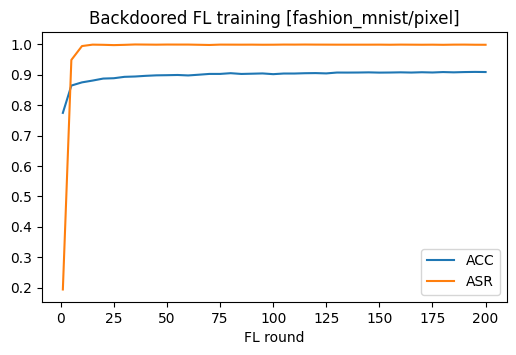


=== fashion_mnist / watermark: watermark "1", factor 0.3 -> target 1 ===
[training] backdoored FL model [fashion_mnist/watermark] ...


[Round   1] ACC=0.7851  ASR=0.3442


[Round   5] ACC=0.8672  ASR=0.8769


[Round  10] ACC=0.8756  ASR=0.9668


[Round  15] ACC=0.8845  ASR=0.9858


[Round  20] ACC=0.8903  ASR=0.9719


... (33 outputs left out)

[Round 190] ACC=0.9076  ASR=0.9959


[Round 195] ACC=0.9087  ASR=0.9934


[Round 200] ACC=0.9093  ASR=0.9918
FL done. Attack scale used: 1.5
[saved checkpoint]  backdoored FL model [fashion_mnist/watermark]  ->  /kaggle/working/backdoored_fashion_mnist_watermark_paper_iid.pt


[Backdoored FL model watermark]  ACC=0.9093  ASR=0.9918


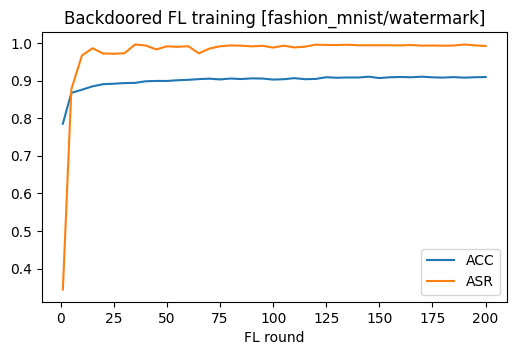

In [14]:
cfg.POISON_RATE = 0.5

def train_backdoored(atk):
    def build():
        m, h = run_federated(attack=atk, attack_scale=ATTACK_SCALE)
        HIST[atk.name] = h
        with open(p(hist_ckpt(atk.name)), "wb") as f:
            pickle.dump(h, f)
        return m
    m = load_or_train(p(bd_ckpt(atk.name)), build, load_classifier, save_state,
                      name=f"backdoored FL model [{DATASET}/{atk.name}]",
                      validate=model_validator(f"backdoored [{DATASET}/{atk.name}]"))
    if atk.name not in HIST and os.path.exists(p(hist_ckpt(atk.name))):
        with open(p(hist_ckpt(atk.name)), "rb") as f: HIST[atk.name] = pickle.load(f)
    return m

test_loader = make_test_loader(test_set)
for atk in ATTACK_LIST:
    print(f"\n=== {DATASET} / {atk.name}: {atk.desc} -> target {atk.target} ===")
    BD[atk.name] = train_backdoored(atk)
    acc_bd, asr_bd = evaluate(BD[atk.name], test_loader, atk)
    print(f"[Backdoored FL model {atk.name}]  ACC={acc_bd:.4f}  ASR={asr_bd:.4f}")
    if atk.strict_asr:
        assert asr_bd > 0.9, "Backdoor not effective - check trigger / rounds / attack scale"
    elif asr_bd < 0.5:
        print(f"  WARNING: ASR {asr_bd:.3f} < 0.5 - the backdoor is weak; consider more rounds / a higher POISON_RATE "
              f"(for the semantic attack ASR is also compared with the teacher's own rate below).")
    h = HIST.get(atk.name)
    if h:
        plt.figure(figsize=(6, 3.5))
        plt.plot(h["rounds"], h["acc"], label="ACC")
        plt.plot(h["rounds"], h["asr"], label="ASR")
        plt.xlabel("FL round"); plt.legend(); plt.title(f"Backdoored FL training [{DATASET}/{atk.name}]"); plt.show()

# primary attack = first one; its model is the "global model" that seeds the GAN
backdoored_model = global_model = BD[ATTACK_LIST[0].name]   # alias; NEVER train it in place - copy into a fresh classifier first
history_bd = HIST.get(ATTACK_LIST[0].name)
acc_bd, asr_bd = evaluate(backdoored_model, test_loader, ATTACK_LIST[0])

## 12. Server clean model (teacher)

In [15]:
n_clean = int(len(train_set) * cfg.CLEAN_RATIO)
clean_idx = np.random.RandomState(1234).choice(len(train_set), n_clean, replace=False)
clean_loader = make_loader(Subset(train_set, clean_idx), 64, shuffle=True)
print(f"Server holds {n_clean} clean samples ({cfg.CLEAN_RATIO*100:.1f}% of train)")

def build_clean():
    torch.manual_seed(SEED)
    return train_clean_model(clean_loader, epochs=cfg.CLEAN_EPOCHS, lr=SPEC.clean_lr,
                             optim=SPEC.clean_optim, wd=SPEC.clean_wd, momentum=SPEC.clean_momentum,
                             sched=SPEC.clean_sched, augment=SPEC.augment)

clean_model = load_or_train(p(CKPT["clean"]), build_clean, load_classifier, save_state,
                            name=f"clean teacher [{DATASET}]", validate=model_validator(f"clean teacher [{DATASET}]"))
teacher = freeze(clean_model)     # teacher IS the frozen clean model
TEACHER = {a.name: evaluate(clean_model, test_loader, a) for a in ATTACK_LIST}   # (ACC, own target-rate T) per attack
acc_clean, asr_clean = TEACHER[ATTACK_LIST[0].name]
for a in ATTACK_LIST:
    print(f"[Clean teacher / {a.name}]  ACC={TEACHER[a.name][0]:.4f}  own target-rate T={TEACHER[a.name][1]:.4f}")

Server holds 1800 clean samples (3.0% of train)
[training] clean teacher [fashion_mnist] ...


[saved checkpoint]  clean teacher [fashion_mnist]  ->  /kaggle/working/clean_fashion_mnist_paper_iid.pt


[Clean teacher / pixel]  ACC=0.7788  own target-rate T=0.0002
[Clean teacher / watermark]  ACC=0.7788  own target-rate T=0.0003


## 13. GAN (model-seeded, paper Algorithm 1)
> The discriminator's convolutional trunk is the Classifier trunk **initialised from the primary attack's backdoored global model** (`backdoored_{DATASET}_{primary}.pt`), with a fresh 1-logit real/fake head. The generator is trained adversarially against it on the clean GAN reference data (`GAN_RATIO`), so generated samples are shaped by features of the backdoored model, as in Algorithm 1 (`D(x) <- G_t`). One GAN (`generator_{DATASET}.pt`) and one distillation set (`distill_{DATASET}.pt`) are shared by all attacks of the dataset (deviation: for the non-primary attack the GAN is seeded from the primary attack's model).

> **Stale checkpoints.** Checkpoints are now namespaced by dataset, so a clean-only `generator.pt` from an older version of this notebook is simply never loaded. To regenerate only the GAN + distillation data of the current dataset, set `FORCE_REGEN_GAN = True` (keeps the FL/teacher checkpoints) or delete `generator_{DATASET}.pt` and `distill_{DATASET}.pt`; `FORCE_RETRAIN = True` recomputes every stage including the FL runs. Set the flag back to `False` afterwards so later re-runs resume from checkpoints.

In [16]:
n_gan = int(len(train_set) * cfg.GAN_RATIO)
gan_idx = np.random.RandomState(999).choice(len(train_set), n_gan, replace=False)
gan_loader = make_loader(RawView(train_set, gan_idx), 64, shuffle=True)
print(f"GAN training set: {len(gan_loader.dataset)} raw samples")

def build_gan():
    torch.manual_seed(SEED)
    g = new_generator()
    # Alg. 1: D(x) <- G_t. Discriminator trunk initialised from the backdoored global model.
    d = new_discriminator(seed_model=backdoored_model)
    g, d = train_gan_dcgan(g, d, gan_loader, epochs=cfg.GAN_EPOCHS,
                           g_lr=cfg.GAN_G_LR, d_lr=cfg.GAN_D_LR,
                           g_steps=cfg.GAN_G_STEPS, inst_noise=cfg.GAN_INST_NOISE)
    return g.eval()

G = load_or_train(p(CKPT["generator"]), build_gan, load_generator, save_state,
                  name=f"generator (model-seeded GAN) [{DATASET}]", force=(FORCE_RETRAIN or FORCE_REGEN_GAN))

GAN training set: 6000 raw samples
[training] generator (model-seeded GAN) [fashion_mnist] ...


  GAN ep 5/30  lossD=0.650  lossG=1.778


  GAN ep 10/30  lossD=0.498  lossG=3.086


  GAN ep 15/30  lossD=0.608  lossG=2.232


  GAN ep 20/30  lossD=0.635  lossG=2.446


  GAN ep 25/30  lossD=0.829  lossG=1.802


  GAN ep 30/30  lossD=0.730  lossG=2.082
[saved checkpoint]  generator (model-seeded GAN) [fashion_mnist]  ->  /kaggle/working/generator_fashion_mnist_paper_iid.pt


## 14. Distillation data (`X_kd`, `y_kd`)

[training] distillation data [fashion_mnist] ...


[saved checkpoint]  distillation data [fashion_mnist]  ->  /kaggle/working/distill_fashion_mnist_paper_iid.pt
X_raw range=[0.00,1.00]  X_kd shape=(10000, 1, 28, 28)
Teacher label distribution on GAN samples: [1764, 59, 2870, 1286, 745, 4, 3093, 23, 152, 4]
GAN samples labeled 1 by clean teacher: 59 / 10000  (0.6%)


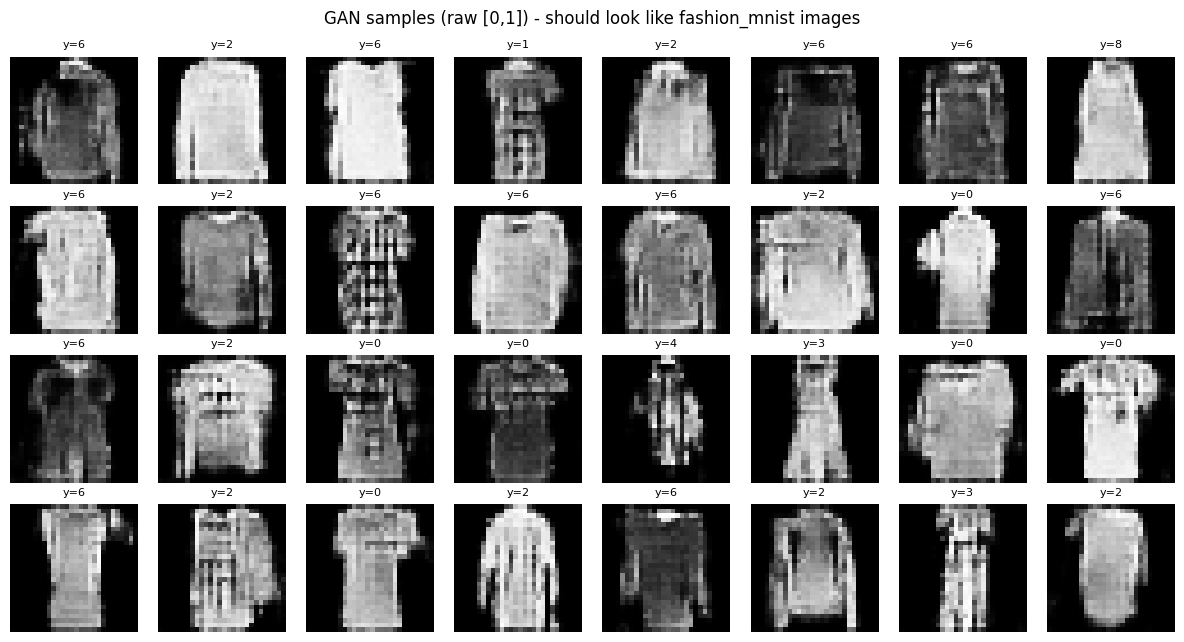

In [17]:
def build_distill():
    torch.manual_seed(SEED + 1)
    X_raw, X_norm, y = generate_distillation_data(G, teacher, n=cfg.N_DISTILL)
    return {"X_raw": X_raw, "X_norm": X_norm, "y": y}

_d = load_or_train(p(CKPT["distill"]), build_distill,
                   lambda path: torch.load(path, map_location="cpu"),
                   lambda obj, path: torch.save(obj, path), name=f"distillation data [{DATASET}]",
                   force=(FORCE_RETRAIN or FORCE_REGEN_GAN))
X_distill_raw = _d["X_raw"]
X_kd, y_kd = _d["X_norm"].to(DEVICE), _d["y"].to(DEVICE)
X_distill, y_distill = X_kd, y_kd          # aliases used by the attack section

print(f"X_raw range=[{X_distill_raw.min():.2f},{X_distill_raw.max():.2f}]  X_kd shape={tuple(X_kd.shape)}")
print(f"Teacher label distribution on GAN samples: {torch.bincount(y_kd.cpu(), minlength=N_CLASSES).tolist()}")
n_t = (y_kd == cfg.TARGET_LABEL).sum().item()
print(f"GAN samples labeled {cfg.TARGET_LABEL} by clean teacher: {n_t} / {len(y_kd)}  ({n_t/len(y_kd)*100:.1f}%)")

def _img(x):   # [C,H,W] raw -> imshow-able
    return x[0].numpy() if x.shape[0] == 1 else x.permute(1, 2, 0).clamp(0, 1).numpy()

fig, axes = plt.subplots(4, 8, figsize=(12, 6.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(_img(X_distill_raw[i]), cmap="gray" if CHANNELS == 1 else None, vmin=0, vmax=1)
    ax.set_title(f"y={y_distill[i].item()}", fontsize=8); ax.axis("off")
plt.suptitle(f"GAN samples (raw [0,1]) - should look like {SPEC.name} images")
plt.tight_layout(); plt.show()

## 15. ADFL: knowledge distillation and evaluation


=== ADFL on fashion_mnist / pixel ===


[Before KD]  ACC=0.9093  ASR=0.9990


  KD ep 5/20  loss=1.0113


  KD ep 10/20  loss=0.4800


  KD ep 15/20  loss=0.3423


  KD ep 20/20  loss=0.2897


[After KD]   ACC=0.6604  ASR=0.0884

ADFL effect:  dACC = -0.2489   dASR = -0.9106
Teacher's own target-rate T = 0.0002  ->  post-ADFL ASR excess over T = +0.0882


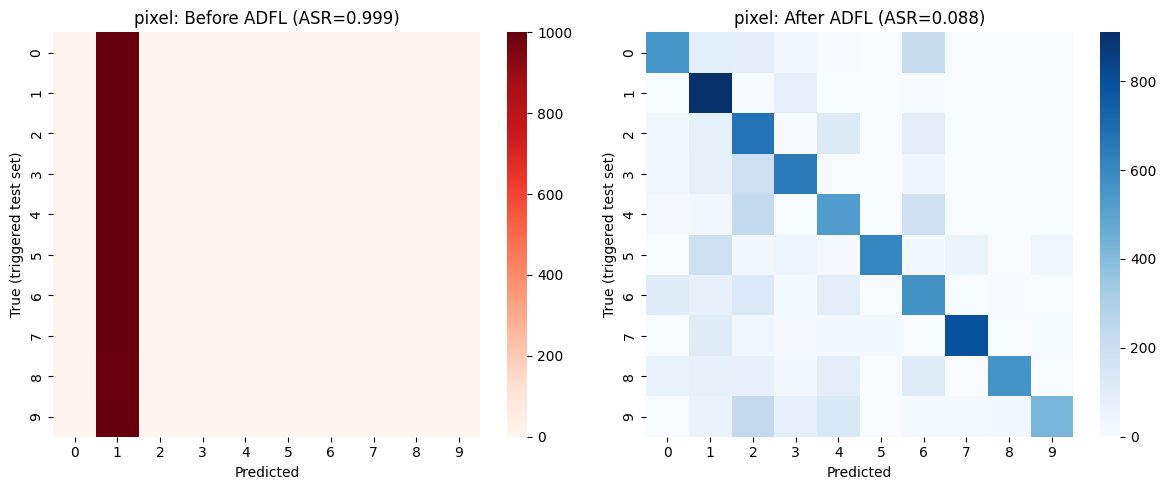


=== ADFL on fashion_mnist / watermark ===


[Before KD]  ACC=0.9093  ASR=0.9918


  KD ep 5/20  loss=1.0181


  KD ep 10/20  loss=0.4644


  KD ep 15/20  loss=0.3271


  KD ep 20/20  loss=0.3145


[After KD]   ACC=0.6979  ASR=0.0033

ADFL effect:  dACC = -0.2114   dASR = -0.9884
Teacher's own target-rate T = 0.0003  ->  post-ADFL ASR excess over T = +0.0030


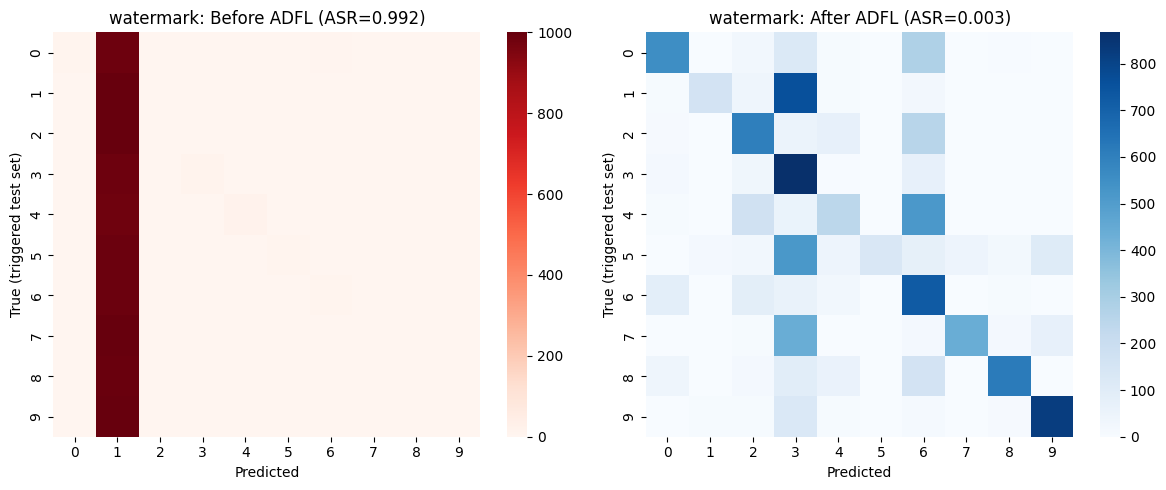

[saved results] /kaggle/working/results_fashion_mnist.json


In [18]:
RESULTS = {}
cm_loader = make_test_loader(test_set, 512)

for atk in ATTACK_LIST:
    print(f"\n=== ADFL on {DATASET} / {atk.name} ===")
    # Fresh copy of the backdoored model (kd_train modifies the student in place)
    student = new_classifier()
    student.load_state_dict(BD[atk.name].state_dict())

    acc_before, asr_before = evaluate(student, test_loader, atk)
    print(f"[Before KD]  ACC={acc_before:.4f}  ASR={asr_before:.4f}")

    student = kd_train(student, teacher, X_kd, y_kd,
                       epochs=cfg.KD_EPOCHS, T=cfg.KD_T, alpha=cfg.KD_ALPHA)
    torch.save(student.state_dict(), p(purified_ckpt(atk.name)))

    acc_after, asr_after = evaluate(student, test_loader, atk)
    T_atk = TEACHER[atk.name][1]
    print(f"[After KD]   ACC={acc_after:.4f}  ASR={asr_after:.4f}")
    print(f"\nADFL effect:  dACC = {acc_after - acc_before:+.4f}   dASR = {asr_after - asr_before:+.4f}")
    print(f"Teacher's own target-rate T = {T_atk:.4f}  ->  post-ADFL ASR excess over T = {asr_after - T_atk:+.4f}")

    row = dict(dataset=DATASET, attack=atk.name, kind=atk.kind, trigger=atk.desc, param=atk.param,
               target=atk.target, asr_pre=asr_before, asr_post=asr_after, acc_pre=acc_before, acc_post=acc_after,
               teacher_T=T_atk, excess_post=asr_after - T_atk, teacher_acc=TEACHER[atk.name][0])
    if atk.kind == "semantic":
        row.update(ctrl_pre=control_rate(BD[atk.name], atk), ctrl_post=control_rate(student, atk),
                   n_subset_test=int(atk.sem_test_mask.sum()))
        print(f"Specificity control (non-attribute images of the source class -> target): "
              f"pre={row['ctrl_pre']:.4f}  post={row['ctrl_post']:.4f}")
    RESULTS[atk.name] = row

    cm_before = triggered_confusion(BD[atk.name], cm_loader, atk)
    cm_after  = triggered_confusion(student, cm_loader, atk)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    sns.heatmap(cm_before, annot=False, cmap="Reds",  ax=axes[0]); axes[0].set_title(f"{atk.name}: Before ADFL (ASR={asr_before:.3f})")
    sns.heatmap(cm_after,  annot=False, cmap="Blues", ax=axes[1]); axes[1].set_title(f"{atk.name}: After ADFL (ASR={asr_after:.3f})")
    for ax in axes: ax.set_xlabel("Predicted"); ax.set_ylabel("True (triggered test set)" if atk.kind != "semantic" else "True (held-out attribute subset)")
    plt.tight_layout(); plt.show()

# primary attack under the legacy variable names
acc_before, asr_before = RESULTS[ATTACK_LIST[0].name]["acc_pre"], RESULTS[ATTACK_LIST[0].name]["asr_pre"]
acc_after,  asr_after  = RESULTS[ATTACK_LIST[0].name]["acc_post"], RESULTS[ATTACK_LIST[0].name]["asr_post"]
save_results()

In [19]:
# ---- Multi-seed rigor: mean +/- std of the headline rows over SEEDS (set SEEDS in the checkpoint cell) ----
# Seed == SEED (42): reuses the single-run checkpoints above untouched (nothing retrained). Every other seed trains
# its own seed-tagged `_s{seed}` backdoored FL model -> model-seeded GAN -> distillation set -> KD, then evaluates
# pre / post ADFL. Fixed across seeds: the client partition, the server clean data and the clean teacher (the
# paper's server data is a fixed set), so the spread measures FL / GAN / KD randomness. Per-seed rows are cached
# in multiseed_{DATASET}{MODEL_TAG}.json; the mean/std fields are merged into RESULTS and results_*.json is rewritten.
_ms_path = p(f"multiseed_{DATASET}{MODEL_TAG}.json")
_ms_cache = json.load(open(_ms_path)) if os.path.exists(_ms_path) else {}     # {str(seed): {attack: row}}

def seed_rows(seed):
    """{attack: dict(asr_pre, acc_pre, asr_post, acc_post)} for one seed (trains missing artifacts; resumable)."""
    if seed == SEED:                                       # existing seed-42 checkpoints
        out = {}
        for atk in ATTACK_LIST:
            if not (os.path.exists(p(bd_ckpt(atk.name))) and os.path.exists(p(purified_ckpt(atk.name)))): return None
            a0, s0 = evaluate(load_classifier(p(bd_ckpt(atk.name))), test_loader, atk)
            a1, s1 = evaluate(load_classifier(p(purified_ckpt(atk.name))), test_loader, atk)
            out[atk.name] = dict(asr_pre=s0, acc_pre=a0, asr_post=s1, acc_post=a1)
        return out
    bds = {}
    for atk in ATTACK_LIST:
        def _fl(atk=atk):
            m, h = run_federated(verbose=False, attack=atk, attack_scale=ATTACK_SCALE, seed=seed)
            with open(p(hist_ckpt(atk.name, seed)), "wb") as f: pickle.dump(h, f)
            return m
        bds[atk.name] = load_or_train(p(bd_ckpt(atk.name, seed)), _fl, load_classifier, save_state,
                                      name=f"backdoored [{DATASET}/{atk.name}] seed={seed}",
                                      validate=model_validator(f"backdoored [{DATASET}/{atk.name}] seed={seed}"))
    def _gan():
        torch.manual_seed(seed)
        g, d = train_gan_dcgan(new_generator(), new_discriminator(seed_model=bds[ATTACK_LIST[0].name]), gan_loader,
                               epochs=cfg.GAN_EPOCHS, g_lr=cfg.GAN_G_LR, d_lr=cfg.GAN_D_LR,
                               g_steps=cfg.GAN_G_STEPS, inst_noise=cfg.GAN_INST_NOISE)
        return g.eval()
    g_s = load_or_train(p(seeded(CKPT["generator"], seed)), _gan, load_generator, save_state,
                        name=f"generator seed={seed}", force=(FORCE_RETRAIN or FORCE_REGEN_GAN))
    def _dist():
        torch.manual_seed(seed + 1)
        Xr, Xn, y = generate_distillation_data(g_s, teacher, n=cfg.N_DISTILL)
        return {"X_raw": Xr, "X_norm": Xn, "y": y}
    d_s = load_or_train(p(seeded(CKPT["distill"], seed)), _dist, lambda q: torch.load(q, map_location="cpu"),
                        lambda o, q: torch.save(o, q), name=f"distillation data seed={seed}",
                        force=(FORCE_RETRAIN or FORCE_REGEN_GAN))
    Xk, yk = d_s["X_norm"].to(DEVICE), d_s["y"].to(DEVICE)
    out = {}
    for atk in ATTACK_LIST:
        st = new_classifier(); st.load_state_dict(bds[atk.name].state_dict())
        a0, s0 = evaluate(st, test_loader, atk)
        torch.manual_seed(seed + 2)
        st = kd_train(st, teacher, Xk, yk, epochs=cfg.KD_EPOCHS, T=cfg.KD_T, alpha=cfg.KD_ALPHA)
        torch.save(st.state_dict(), p(purified_ckpt(atk.name, seed)))
        a1, s1 = evaluate(st, test_loader, atk)
        out[atk.name] = dict(asr_pre=s0, acc_pre=a0, asr_post=s1, acc_post=a1)
        print(f"  seed={seed} {atk.name}: pre ASR={s0:.4f} ACC={a0:.4f} | post ASR={s1:.4f} ACC={a1:.4f}")
    return out

def aggregate_seeds(per_seed):
    """per_seed: {seed: row}. Returns mean/std (sample std, ddof=1) fields for asr/acc pre/post + n_seeds + seeds."""
    seeds = sorted(per_seed); agg = dict(n_seeds=len(seeds), seeds=seeds)
    for k in ("asr_pre", "asr_post", "acc_pre", "acc_post"):
        v = np.array([per_seed[s][k] for s in seeds], dtype=float)
        agg[k + "_mean"] = float(v.mean()); agg[k + "_std"] = float(v.std(ddof=1)) if len(v) > 1 else 0.0
    return agg

if len(SEEDS) < 2:
    print(f"SEEDS={SEEDS}: single seed -> nothing to aggregate (set SEEDS=[42, 43, 44] in the checkpoint cell for mean+/-std).")
elif teacher is None:
    print("Multi-seed skipped: the clean teacher is missing (run the pipeline / reload_all() first).")
else:
    PER_SEED = {}                                              # seed -> {attack: row}
    for s in SEEDS:
        if s != SEED and str(s) in _ms_cache: PER_SEED[s] = _ms_cache[str(s)]; continue   # cached per-seed rows
        rows_s = seed_rows(s)
        if rows_s is None: print(f"seed={s}: seed-{SEED} checkpoints missing (run the cells above first)"); continue
        PER_SEED[s] = rows_s
        if s != SEED:
            _ms_cache[str(s)] = _jsonable(rows_s)
            with open(_ms_path, "w") as f: json.dump(_ms_cache, f, indent=2)
    MULTISEED = {}
    for atk in ATTACK_LIST:
        ps = {s: r[atk.name] for s, r in PER_SEED.items() if atk.name in r}
        if len(ps) < 2: continue
        m = MULTISEED[atk.name] = aggregate_seeds(ps)
        if atk.name in RESULTS: RESULTS[atk.name].update(m)    # scalar fields stay = seed-SEED values
        print(f"{DATASET}/{atk.name}  n={m['n_seeds']} seeds={m['seeds']}:  "
              f"ASR pre {m['asr_pre_mean']:.3f}+/-{m['asr_pre_std']:.3f}  post {m['asr_post_mean']:.3f}+/-{m['asr_post_std']:.3f}  "
              f"ACC post {m['acc_post_mean']:.3f}+/-{m['acc_post_std']:.3f}")
    if RESULTS and MULTISEED: save_results()

SEEDS=[42]: single seed -> nothing to aggregate (set SEEDS=[42, 43, 44] in the checkpoint cell for mean+/-std).


## 16. Attack experiments (OOD / Path-B evasion screen), per dataset

> **NOTE - the GAN is model-seeded (Phase A).** The distillation set is built from a generator trained against a discriminator initialised from the backdoored global model, as in the paper's Algorithm 1, so generated samples can carry backdoor-relevant features. Survival results in this section are therefore meaningful tests against ADFL-as-designed rather than a test-bed artefact - **but only once a candidate is confirmed by a full FL + ADFL run**: the centralized proxy screen (`screen_trigger`) is a cheap filter, not evidence of evasion. Do not interpret numbers produced from an old clean-only generator.

The screen is run for the active dataset: candidate trigger shapes (defined on a 28-px reference grid and scaled to the active image size, with per-channel colors for CIFAR-10) are screened with a centralized proxy backdoor; the top non-degenerate survivors (whole-image-overwrite patches are skipped) plus any *pinned* candidate (MNIST: `three_corners`, the Phase-A candidate) are then **full-FL-confirmed** with `full_fl_adfl` and counted as an evasion only if they survive there. `full_fl_adfl` takes its attack explicitly, so the canonical `ATTACK` is never modified.

In [20]:
# ---- Candidate trigger builders (patch format: (row, col, h, w, value); value scalar or per-channel tuple) ----
def S(v):
    """Scale a coordinate/length from the 28-px reference grid to the active image size (identity for 28)."""
    return int(round(v * SIZE / 28))

def R(r, c, h, w, v=1.0):
    """Reference-grid rectangle -> active-size rectangle (never thinner than 1 px)."""
    return (S(r), S(c), max(1, S(h)), max(1, S(w)), v)

def _rand_vals(rng, lo, hi, h, w):
    # 1-channel draw shape is unchanged from the original MNIST notebook
    return rng.uniform(lo, hi, (h, w)) if CHANNELS == 1 else rng.uniform(lo, hi, (h, w, CHANNELS))

def _px(vals, i, j):
    return float(vals[i, j]) if CHANNELS == 1 else tuple(float(t) for t in vals[i, j])

def random_patch_patches(r0, c0, h, w, seed=0, lo=-1.0, hi=1.0):
    """Fixed random patch; returns a list of (r,c,1,1,v) single-pixel patches.
    NOTE (value space): docs call lo/hi 'normalized space', but apply_trigger treats
    patch values as RAW pixels, so low-amplitude patches (lo<0) contain negative pixels.
    Behavior intentionally kept as in the original notebook."""
    rng = np.random.RandomState(seed)
    vals = _rand_vals(rng, lo, hi, h, w)
    return [(r0+i, c0+j, 1, 1, _px(vals, i, j)) for i in range(h) for j in range(w)]

random_patch = random_patch_patches          # alias used by older cells

def random_pixel_patch(r0, c0, h, w, seed=0, lo=0.0, hi=1.0):
    """Random patch with values in RAW pixel space [lo, hi] within [0,1]."""
    rng = np.random.RandomState(seed)
    vals = _rand_vals(rng, lo, hi, h, w)
    return [(r0+i, c0+j, 1, 1, _px(vals, i, j)) for i in range(h) for j in range(w)]

def low_amp_normalized_patch(seed=0, amp=0.3, h=None, w=None):
    """Amplitude `amp` in NORMALIZED space, converted to raw pixel space (in-support)."""
    h = SIZE if h is None else h; w = SIZE if w is None else w
    rng = np.random.RandomState(seed)
    u = _rand_vals(rng, -amp, amp, h, w)
    vals_pixel = np.array(SPEC.mean) + np.array(SPEC.std) * u      # per channel
    return [(i, j, 1, 1, _px(vals_pixel, i, j)) for i in range(h) for j in range(w)]

def patch_coverage(patches):
    """Fraction of image pixels overwritten by a patch list."""
    m = np.zeros((SIZE, SIZE), bool)
    for (r, c, h, w, _) in patches: m[r:r+h, c:c+w] = True
    return m.mean()


# ---- Proxy backdoor trainer (centralized, NOT FL) ----
def quick_backdoor(train_set, attack, n_poison=3000, epochs=None, seed=0):
    assert attack.kind in ("pixel", "watermark"), "proxy screen supports trigger-type attacks only"
    epochs = cfg.QB_EPOCHS if epochs is None else epochs
    model = new_classifier()
    opt = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
    rng = np.random.RandomState(seed)
    if cfg.QB_N_TRAIN is None:
        indices = range(len(train_set))
        poison_set = set(rng.choice(len(train_set), n_poison, replace=False).tolist())
    else:
        indices = rng.choice(len(train_set), cfg.QB_N_TRAIN, replace=False).tolist()
        poison_set = set(rng.choice(indices, min(n_poison, len(indices) // 2), replace=False).tolist())
    view = PoisonedView(train_set, indices, poison_set, attack)
    loader = make_loader(view, 64, shuffle=True)
    for ep in range(epochs):
        model.train()
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            F.cross_entropy(model(x), y).backward()
            opt.step()
    return model


def screen_trigger(name, attack):
    """1) teacher's rate on triggered inputs (T); 2) proxy backdoor; 3) ADFL KD; report excess = post - T."""
    T_trigger = teacher_rate(attack)

    if T_trigger > 0.20:
        print(f"{name:40s}  T={T_trigger:.3f}  SKIP (T too high)")
        return None

    model_bd = quick_backdoor(train_set, attack)
    acc_pre, asr_pre = evaluate(model_bd, test_loader, attack)
    if asr_pre < 0.80:
        print(f"{name:40s}  T={T_trigger:.3f}  pre={asr_pre:.3f}  SKIP (backdoor weak)")
        return None

    model_post = new_classifier()                      # fresh copy to avoid aliasing
    model_post.load_state_dict(model_bd.state_dict())
    model_post = kd_train(model_post, teacher, X_kd, y_kd,
                          epochs=cfg.KD_EPOCHS, T=cfg.KD_T, alpha=cfg.KD_ALPHA)

    acc_post, asr_post = evaluate(model_post, test_loader, attack)
    excess = asr_post - T_trigger
    verdict = ""
    if excess > 0.15:   verdict = "  <-- SUCCESS (Path B candidate!)"
    elif excess > 0.05: verdict = "  <-- partial"
    print(f"{name:40s}  T={T_trigger:.3f}  pre={asr_pre:.3f}  post={asr_post:.3f}  excess={excess:+.3f}{verdict}")
    return dict(name=name, T=T_trigger, pre=asr_pre, post=asr_post, excess=excess, atk_obj=attack)

In [21]:
# ---- Screen 1: broad candidate families (28-px reference geometry, scaled to the active size) ----
def _stripes_h(): return [(r, 0, 1, SIZE, 1.0) for r in range(0, SIZE, 3)]
def _stripes_v(): return [(0, c, SIZE, 1, 1.0) for c in range(0, SIZE, 3)]
_corners = lambda: [R(2, 2, 5, 5), R(11, 11, 5, 5), R(21, 21, 5, 5)]

candidates = [
    ("random_14x14_center",    random_patch_patches(S(7), S(7), S(14), S(14), seed=1)),
    ("random_20x20_center",    random_patch_patches(S(4), S(4), S(20), S(20), seed=1)),
    ("white_14x14_center",     [R(7, 7, 14, 14)]),
    ("white_20x20_center",     [R(4, 4, 20, 20)]),
    ("horizontal_stripes",     _stripes_h()),
    ("vertical_stripes",       _stripes_v()),
    ("nine_dots",              [R(r, c, 2, 2) for r in [4, 12, 22] for c in [4, 12, 22]
                                if not (r == 12 and c == 12)]),
    ("three_corners",          _corners()),
    ("cross_center",           [R(2, 12, 24, 3), R(12, 2, 3, 24)]),
    ("hollow_square",          [R(4, 4, 2, 20), R(22, 4, 2, 20), R(4, 4, 20, 2), R(4, 22, 20, 2)]),
    ("low_amp_noise",          random_patch_patches(0, 0, SIZE, SIZE, seed=2, lo=-0.3, hi=0.3)),
    ("low_amp_full",           random_patch_patches(0, 0, SIZE, SIZE, seed=3, lo=-0.1, hi=0.1)),
]
if cfg.ATTACK_MAX_CANDIDATES: candidates = candidates[:cfg.ATTACK_MAX_CANDIDATES]
CAND = dict(candidates)         # name -> patches (also used to look up pinned candidates)

results_v1 = []
for name, patches in ([] if EXPERIMENT else candidates):
    print(f"  [{name}: covers {patch_coverage(patches):.0%} of the image]", end="")
    r = screen_trigger(name, pixel_attack(name, patches))
    if r: results_v1.append(r)

  [random_14x14_center: covers 25% of the image]

  KD ep 5/20  loss=0.5637


  KD ep 10/20  loss=0.2827


  KD ep 15/20  loss=0.2486


  KD ep 20/20  loss=0.2218


random_14x14_center                       T=0.000  pre=1.000  post=0.001  excess=+0.001
  [random_20x20_center: covers 51% of the image]

... (51 outputs left out)

  KD ep 10/20  loss=0.2769


  KD ep 15/20  loss=0.2519


  KD ep 20/20  loss=0.2251


low_amp_full                              T=0.000  pre=1.000  post=0.000  excess=+0.000


In [22]:
# ---- Screen 2: value-space-corrected variants (in-support pixel ranges) ----
corrected = [
    ("random_14x14_pixel",   random_pixel_patch(S(7), S(7), S(14), S(14), seed=1, lo=0.0, hi=1.0)),
    ("random_20x20_pixel",   random_pixel_patch(S(4), S(4), S(20), S(20), seed=1, lo=0.0, hi=1.0)),
    ("low_amp_norm_03",      low_amp_normalized_patch(seed=2, amp=0.3)),
    ("low_amp_norm_01",      low_amp_normalized_patch(seed=3, amp=0.1)),
    ("white_14x14",          [R(7, 7, 14, 14)]),
    ("stripes_h",            _stripes_h()),
    ("three_corners",        _corners()),
]
if cfg.ATTACK_MAX_CANDIDATES: corrected = corrected[:cfg.ATTACK_MAX_CANDIDATES]
for _n, _pt in corrected: CAND.setdefault(_n, _pt)

results_v2 = []
for name, patches in ([] if EXPERIMENT else corrected):
    print(f"  [{name}: covers {patch_coverage(patches):.0%} of the image]", end="")
    r = screen_trigger(name, pixel_attack(name, patches))
    if r: results_v2.append(r)

print("\nCorrected summary (sorted by excess):")
for r in sorted(results_v2, key=lambda x: -x["excess"]):
    print(f"  {r['name']:25s}  T={r['T']:.3f}  pre={r['pre']:.3f}  post={r['post']:.3f}  excess={r['excess']:+.3f}")
SCREEN[:] = [{k: v for k, v in r.items() if k != "atk_obj"} for r in results_v1 + results_v2]

  [random_14x14_pixel: covers 25% of the image]

  KD ep 5/20  loss=0.5537


  KD ep 10/20  loss=0.2862


  KD ep 15/20  loss=0.2419


  KD ep 20/20  loss=0.2211


random_14x14_pixel                        T=0.000  pre=1.000  post=0.701  excess=+0.701  <-- SUCCESS (Path B candidate!)
  [random_20x20_pixel: covers 51% of the image]

... (26 outputs left out)

  KD ep 10/20  loss=0.2771


  KD ep 15/20  loss=0.2440


  KD ep 20/20  loss=0.2181


three_corners                             T=0.000  pre=0.999  post=0.581  excess=+0.581  <-- SUCCESS (Path B candidate!)

Corrected summary (sorted by excess):
  low_amp_norm_03            T=0.000  pre=1.000  post=1.000  excess=+1.000
  low_amp_norm_01            T=0.000  pre=1.000  post=1.000  excess=+1.000
  random_14x14_pixel         T=0.000  pre=1.000  post=0.701  excess=+0.701
  three_corners              T=0.000  pre=0.999  post=0.581  excess=+0.581
  white_14x14                T=0.000  pre=0.943  post=0.138  excess=+0.138
  stripes_h                  T=0.000  pre=1.000  post=0.133  excess=+0.133
  random_20x20_pixel         T=0.000  pre=1.000  post=0.014  excess=+0.014


In [23]:
# ---- Full-FL confirmation of a screened trigger (checkpointed, multi-seed over SEEDS) ----
def _distill_set_for_seed(seed):
    """(X_kd, y_kd) for one seed. Seed 42 reuses the single-run globals; every other seed reloads
    that seed's cached GAN generator and regenerates the distillation set (the clean teacher is
    held fixed across seeds, matching the multi-seed base section). Mirrors cell 32 exactly:
    X_kd is the NORMALIZED distillation set, moved to DEVICE."""
    if seed == SEED:
        return X_kd, y_kd
    g_s = load_generator(p(seeded(CKPT["generator"], seed)))
    torch.manual_seed(seed + 1)
    _Xr, Xn, y = generate_distillation_data(g_s, teacher, n=cfg.N_DISTILL)
    return Xn.to(DEVICE), y.to(DEVICE)


def _full_fl_adfl_one(name, patches, seed, alpha=None, n_rounds=None):
    """One seed: full FL with the pixel-patch attack (seed-namespaced checkpoint), then ADFL KD
    with that seed's distillation set. The attack is passed explicitly to run_federated / evaluate,
    so the live ATTACK global is never touched."""
    alpha = cfg.KD_ALPHA if alpha is None else alpha
    attack = pixel_attack(name, patches)
    model_fl = load_or_train(p(bd_ckpt(name, seed)),
                             lambda: run_federated(attack=attack, attack_scale=ATTACK_SCALE, n_rounds=n_rounds,
                                                   poison_rate=0.5, seed=seed)[0],
                             load_classifier, save_state,
                             name=f"backdoored FL model [{DATASET}/{name}] seed={seed}",
                             validate=model_validator(f"backdoored FL [{DATASET}/{name}] seed={seed}"))
    T = teacher_rate(attack)
    acc_pre, asr_pre = evaluate(model_fl, test_loader, attack)

    Xk, yk = _distill_set_for_seed(seed)
    student = new_classifier()
    student.load_state_dict(model_fl.state_dict())
    student = kd_train(student, teacher, Xk, yk, epochs=cfg.KD_EPOCHS, T=cfg.KD_T, alpha=alpha)
    acc_post, asr_post = evaluate(student, test_loader, attack)

    torch.save(student.state_dict(), p(purified_ckpt(name, seed)))
    return dict(T=T, asr_pre=asr_pre, asr_post=asr_post, acc_pre=acc_pre, acc_post=acc_post)


def full_fl_adfl(name, patches, alpha=None, n_rounds=None):
    """Multi-seed full-FL + ADFL confirmation over SEEDS. Reports mean +/- std (sample std, ddof=1)
    of post-ADFL ASR / ACC across seeds; excess = (mean post ASR) - T. Seed 42 reuses the existing
    single-run _FL_ checkpoints and distillation globals, so SEEDS=[42] reproduces the original
    single-run behaviour exactly."""
    per = [_full_fl_adfl_one(name, patches, s, alpha, n_rounds) for s in SEEDS]

    def _ms(k):
        v = np.array([r[k] for r in per], dtype=float)
        return float(v.mean()), (float(v.std(ddof=1)) if len(v) > 1 else 0.0)

    T = per[0]["T"]
    asr_pre_m,  asr_pre_s  = _ms("asr_pre")
    asr_post_m, asr_post_s = _ms("asr_post")
    acc_pre_m,  acc_pre_s  = _ms("acc_pre")
    acc_post_m, acc_post_s = _ms("acc_post")
    excess = asr_post_m - T

    if   excess > 0.15: verdict = "REAL PATH-B WINNER"
    elif excess > 0.05: verdict = "partial (full-FL weaker than screen)"
    else:               verdict = "ADFL removed it"
    print(f"\n[{name}]  n={len(SEEDS)} seeds={SEEDS}  T={T:.3f}  pre={asr_pre_m:.4f}  "
          f"post={asr_post_m:.4f}+/-{asr_post_s:.4f}  excess={excess:+.3f}  <-- {verdict}")
    print(f"  ACC: pre={acc_pre_m:.4f}  post={acc_post_m:.4f}+/-{acc_post_s:.4f}")

    return dict(name=name, T=T, n_seeds=len(SEEDS), seeds=list(SEEDS),
                asr_pre=asr_pre_m, asr_post=asr_post_m,
                asr_pre_mean=asr_pre_m, asr_pre_std=asr_pre_s,
                asr_post_mean=asr_post_m, asr_post_std=asr_post_s,
                acc_pre=acc_pre_m, acc_pre_mean=acc_pre_m, acc_pre_std=acc_pre_s,
                acc_post=acc_post_m, acc_post_mean=acc_post_m, acc_post_std=acc_post_s,
                excess=excess, verdict=verdict)


def pick_for_confirmation(results, k):
    """Top-k non-degenerate screen survivors (excess > 0.05), with the spec's pinned candidates always
    included. Whole-image-overwrite patches (>= 90% coverage, e.g. the low-amplitude full-image noise)
    are skipped: they replace the image rather than trigger it. If nothing survived, confirm the single
    best-scoring non-degenerate candidate so the run still reports a full-FL data point."""
    best = {}
    for r in results:
        if r["name"] not in best or r["excess"] > best[r["name"]]["excess"]:
            best[r["name"]] = r
    nondeg = [r for r in best.values() if patch_coverage(r["atk_obj"].patches) < 0.9]
    skipped = [r["name"] for r in best.values() if r not in nondeg]
    if skipped: print("Skipped as whole-image-overwrite:", skipped)
    surv = sorted([r for r in nondeg if r["excess"] > 0.05], key=lambda r: -r["excess"])
    chosen = [(n, CAND[n]) for n in SPEC.pinned_evasion if n in CAND]
    for r in surv:
        if len(chosen) >= k: break
        if r["name"] not in [c[0] for c in chosen]: chosen.append((r["name"], r["atk_obj"].patches))
    if not chosen and nondeg:
        r = max(nondeg, key=lambda r: r["excess"])
        print(f"No screen survivors (excess > 0.05); confirming the best-scoring candidate {r['name']} anyway.")
        chosen.append((r["name"], r["atk_obj"].patches))
    return chosen[:max(k, len(SPEC.pinned_evasion))]


to_confirm = [] if EXPERIMENT else pick_for_confirmation(results_v1 + results_v2, cfg.EVASION_TOPK)
print("Full-FL confirmation list:", [n for n, _ in to_confirm])
fl_results = [full_fl_adfl(f"{n}_FL", pt) for n, pt in to_confirm]
assert ATTACK is ATTACK_LIST[0]    # canonical attack untouched

print("\n=== Full-FL summary (mean +/- std over seeds) ===")
for r in fl_results:
    print(f"  {r['name']:24s}  T={r['T']:.3f}  pre={r['asr_pre']:.3f}  "
          f"post={r['asr_post']:.3f}+/-{r.get('asr_post_std', 0.0):.3f}  excess={r['excess']:+.3f}  {r['verdict']}")
if not any(r["excess"] > 0.15 for r in fl_results):
    print("\nNo full-FL-confirmed evasion for this dataset: every confirmed candidate was removed (or only partially survived) under ADFL.")
EVASION[:] = fl_results
save_results()


Skipped as whole-image-overwrite: ['low_amp_noise', 'low_amp_full', 'low_amp_norm_03', 'low_amp_norm_01']
Full-FL confirmation list: ['random_14x14_pixel', 'horizontal_stripes', 'three_corners']
[training] backdoored FL model [fashion_mnist/random_14x14_pixel_FL] ...


[Round   1] ACC=0.7798  ASR=0.2391


[Round   5] ACC=0.8682  ASR=0.8961


[Round  10] ACC=0.8773  ASR=0.9982


[Round  15] ACC=0.8855  ASR=0.9991


[Round  20] ACC=0.8911  ASR=0.9981


... (117 outputs left out)

[Round 150] ACC=0.9075  ASR=0.9997


[Round 155] ACC=0.9072  ASR=0.9996


[Round 160] ACC=0.9093  ASR=0.9994


[Round 165] ACC=0.9084  ASR=0.9993


In [ ]:
# ---- Watermark blend-factor sweep (cheap centralized proxy screen; paper factors ~0.1 / 0.3 / 0.5) ----
WM_SWEEP[:] = []
if (not EXPERIMENT) and any(c["kind"] == "watermark" for c in SPEC.attack_cfgs):
    _wm = make_watermark(SIZE, CHANNELS)
    for f in (0.1, 0.3, 0.5):
        a = AttackSpec(name=f"watermark_f{f}", kind="watermark", target=SPEC.target_label, wm=_wm,
                       factor=f, param=f, desc=f'watermark "1", factor {f}')
        r = screen_trigger(a.name, a)
        if r: WM_SWEEP.append({k: v for k, v in r.items() if k != "atk_obj"} | {"factor": f})
    save_results()
else:
    print("No watermark attack registered for this dataset - sweep skipped.")

## 16b. Clean-data budget sweep (ADFL accuracy tax vs CLEAN_RATIO)

Does ADFL's accuracy collapse come from the defense itself or just from a small clean set? This varies only the server's clean budget (teacher + distillation labels), holding the GAN and the backdoored model fixed, and plots post-ADFL ACC/ASR against it. Cheap on grayscale; run in the Fashion-MNIST session.

In [ ]:
# ---- Clean-data budget sweep: how ADFL's accuracy tax depends on CLEAN_RATIO ----
# Controlled experiment behind the "ADFL's post-defense accuracy is bounded by a clean-data-
# trained teacher" critique. We vary ONLY the server's clean budget: at each ratio we retrain
# the clean teacher, relabel the SAME (already-trained, model-seeded) GAN samples with it, and
# run KD on a fresh copy of the SAME backdoored model. The GAN and the backdoored model are held
# fixed, so any change in post-ADFL ACC / ASR is attributable to the clean budget alone.
# Cheap on the grayscale sets; run it in the Fashion-MNIST session (DATASET="fashion_mnist").

import copy
SWEEP_RATIOS = [0.03, 0.05, 0.10, 0.20]   # fractions of the train set given to the server
FORCE_SWEEP  = False                      # True = recompute even if clean_sweep_{DATASET}.json exists
_sweep_path  = p(f"clean_sweep_{DATASET}{MODEL_TAG}.json")

atk_sw = ATTACK_LIST[0]                    # primary attack (Fashion: the 5x5 pixel block)
bd_sw  = BD.get(atk_sw.name, backdoored_model)

if bd_sw is None or G is None:
    print("Clean-ratio sweep skipped: need a trained backdoored model + GAN "
          "(run the pipeline for this DATASET first, or reload_all()).")
elif os.path.exists(_sweep_path) and not FORCE_SWEEP:
    with open(_sweep_path) as f: _loaded = json.load(f)
    CLEAN_SWEEP = _loaded["sweep"] if isinstance(_loaded, dict) else _loaded   # file is {..., "sweep": [...]}
    print(f"[loaded] clean-ratio sweep <- {_sweep_path}")
else:
    acc_pre_sw, asr_pre_sw = evaluate(bd_sw, test_loader, atk_sw)
    print(f"Sweep on {DATASET} / {atk_sw.name}.  Backdoored model: ACC={acc_pre_sw:.4f} ASR={asr_pre_sw:.4f}")
    print(f"Fixed: GAN (model-seeded) and backdoored model.  Varying: CLEAN_RATIO in {SWEEP_RATIOS}\n")
    CLEAN_SWEEP = []
    for r in SWEEP_RATIOS:
        n = int(len(train_set) * r)
        idx = np.random.RandomState(1234).choice(len(train_set), n, replace=False)  # same seed as the main teacher
        loader = make_loader(Subset(train_set, idx), 64, shuffle=True)

        torch.manual_seed(SEED)
        tch = freeze(train_clean_model(loader, epochs=cfg.CLEAN_EPOCHS, lr=SPEC.clean_lr,
                                       optim=SPEC.clean_optim, wd=SPEC.clean_wd, momentum=SPEC.clean_momentum,
                                       sched=SPEC.clean_sched, augment=SPEC.augment))
        t_acc, t_T = evaluate(tch, test_loader, atk_sw)

        torch.manual_seed(SEED + 1)                                     # relabel the SAME GAN with this teacher
        _, Xn, yk = generate_distillation_data(G, tch, n=cfg.N_DISTILL)
        Xn, yk = Xn.to(DEVICE), yk.to(DEVICE)

        student = new_classifier(); student.load_state_dict(bd_sw.state_dict())   # fresh copy of the backdoored model
        kd_train(student, tch, Xn, yk, epochs=cfg.KD_EPOCHS, T=cfg.KD_T, alpha=cfg.KD_ALPHA)
        a_post, s_post = evaluate(student, test_loader, atk_sw)

        row = dict(clean_ratio=r, n_clean=int(n), teacher_acc=float(t_acc), teacher_T=float(t_T),
                   acc_post=float(a_post), asr_post=float(s_post))
        CLEAN_SWEEP.append(row)
        print(f"  ratio={r:>4}  n={n:>5}  teacher ACC={t_acc:.4f}  ->  post-ADFL ACC={a_post:.4f}  ASR={s_post:.4f}")

    with open(_sweep_path, "w") as f:
        json.dump(dict(dataset=DATASET, attack=atk_sw.name,
                       acc_pre=float(acc_pre_sw), asr_pre=float(asr_pre_sw), sweep=CLEAN_SWEEP), f, indent=2)
    print(f"\n[saved] clean-ratio sweep -> {_sweep_path}")

# ---- table + plot ----
if 'CLEAN_SWEEP' in dir() and CLEAN_SWEEP:
    print(f"\n=== ADFL accuracy tax vs server clean-data budget ({DATASET} / {atk_sw.name}) ===")
    print(f"{'clean_ratio':>11} {'n_clean':>8} {'teacher ACC':>12} {'post ACC':>9} {'post ASR':>9}")
    for row in CLEAN_SWEEP:
        print(f"{row['clean_ratio']:>11} {row['n_clean']:>8} {row['teacher_acc']:>12.4f} "
              f"{row['acc_post']:>9.4f} {row['asr_post']:>9.4f}")

    rr  = [row['clean_ratio'] for row in CLEAN_SWEEP]
    tac = [row['teacher_acc'] for row in CLEAN_SWEEP]
    pac = [row['acc_post']    for row in CLEAN_SWEEP]
    pas = [row['asr_post']    for row in CLEAN_SWEEP]

    fig, ax1 = plt.subplots(figsize=(7, 4.2))
    ax1.plot(rr, pac, "o-",  color="#27ae60", label="post-ADFL ACC")
    ax1.plot(rr, tac, "s--", color="#7f8c8d", label="clean teacher ACC")
    ax1.axhline(0.90, color="#c0392b", ls=":", lw=1, label="paper claim (ACC > 0.90)")
    ax1.set_xlabel("server clean-data budget (CLEAN_RATIO)"); ax1.set_ylabel("accuracy")
    ax1.set_ylim(0, 1.02); ax1.set_xticks(rr)
    ax2 = ax1.twinx()
    ax2.plot(rr, pas, "^-", color="#2e86c1", label="post-ADFL ASR")
    ax2.set_ylabel("post-ADFL ASR", color="#2e86c1"); ax2.set_ylim(0, 1.02)
    ax2.tick_params(axis="y", labelcolor="#2e86c1")
    h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, fontsize=8, loc="center right")
    plt.title(f"ADFL vs clean-data budget - {DATASET} / {atk_sw.name}")
    plt.tight_layout(); plt.show()


## 16c. KD learning-rate knee (CIFAR): can stronger KD remove the backdoor?

The KD-epoch sweep showed post-ADFL ASR is flat in epochs while accuracy bleeds, i.e. at KD_LR=5e-4 distillation never reaches the backdoor. This cell holds the backdoored model, teacher and GAN distillation set fixed and varies only the KD **learning rate**, on the **canonical pixel attack** (the real removal test). Pick the KD_LR where the backdoor drops (low ASR) while ACC is retained; if ASR stays high at every usable KD_LR, ADFL structurally cannot remove this corner trigger on CIFAR. CIFAR-10 only; tune cheaply with CIFAR_MODEL="cnn".

In [ ]:
# ---- KD learning-rate sweep (CIFAR): can stronger KD actually remove the backdoor? ----
# The KD-epoch sweep showed post-ADFL ASR is FLAT in epochs while ACC bleeds -> at KD_LR=5e-4
# the distillation never reaches the backdoor subnetwork. This sweep holds everything fixed
# (backdoored model, teacher, GAN distillation set X_kd/y_kd) and varies ONLY the KD learning
# rate, on the CANONICAL PIXEL attack (the real removal test; semantic is a weak 0.55 backdoor).
# Each point starts from a fresh copy of the pixel backdoored model. We want a KD_LR where the
# backdoor is removed (low ASR) while ACC is retained; if ASR stays high at every usable KD_LR,
# ADFL structurally cannot remove this off-manifold corner trigger on CIFAR (a finding in itself).
# Cheap: reuses the trained teacher + GAN, no FL/GAN retrain. CIFAR-10 only (tune with CNN).

import copy
KD_LR_GRID    = [5e-4, 1e-3, 2e-3, 4e-3, 8e-3]
KD_SWEEP_EP   = 12                        # fixed epochs (a touch longer than the override, to give removal a chance)
FORCE_KD_SWEEP = False                    # True = recompute even if the checkpoint json exists
_kd_sweep_path = p(f"kd_lr_sweep_{DATASET}{MODEL_TAG}.json")

atk_kd = next((a for a in ATTACK_LIST if a.name == "pixel"), ATTACK_LIST[-1])   # canonical pixel attack
bd_kd  = BD.get(atk_kd.name, backdoored_model)

if DATASET != "cifar10":
    print(f"KD-LR sweep skipped: intended for DATASET='cifar10' (current: {DATASET!r}).")
elif bd_kd is None or teacher is None or X_kd is None or y_kd is None:
    print("KD-LR sweep skipped: need the backdoored model, teacher and distillation set "
          "(run the pipeline for this DATASET first, or reload_all()).")
elif os.path.exists(_kd_sweep_path) and not FORCE_KD_SWEEP:
    with open(_kd_sweep_path) as f: KD_SWEEP = json.load(f)["sweep"]
    print(f"[loaded] KD-LR sweep <- {_kd_sweep_path}")
else:
    acc_pre_kd, asr_pre_kd = evaluate(bd_kd, test_loader, atk_kd)
    print(f"KD-LR sweep on {DATASET}{MODEL_TAG} / {atk_kd.name} (epochs={KD_SWEEP_EP}).  "
          f"Backdoored: ACC={acc_pre_kd:.4f} ASR={asr_pre_kd:.4f}")
    print(f"Fixed: teacher + GAN distillation set + KD epochs.  Varying: KD_LR in {KD_LR_GRID}\n")
    KD_SWEEP = []
    for lr in KD_LR_GRID:
        torch.manual_seed(SEED)
        student = new_classifier(); student.load_state_dict(bd_kd.state_dict())   # fresh copy of the backdoored model
        kd_train(student, teacher, X_kd, y_kd, epochs=KD_SWEEP_EP, T=cfg.KD_T, alpha=cfg.KD_ALPHA, lr=lr)
        a_post, s_post = evaluate(student, test_loader, atk_kd)
        KD_SWEEP.append(dict(kd_lr=float(lr), acc_post=float(a_post), asr_post=float(s_post)))
        print(f"  KD_LR={lr:<7.0e}  ->  post-ADFL ACC={a_post:.4f}  ASR={s_post:.4f}")
    with open(_kd_sweep_path, "w") as f:
        json.dump(dict(dataset=DATASET, model=cfg.CIFAR_MODEL, attack=atk_kd.name, kd_epochs=KD_SWEEP_EP,
                       acc_pre=float(acc_pre_kd), asr_pre=float(asr_pre_kd), sweep=KD_SWEEP), f, indent=2)
    print(f"\n[saved] KD-LR sweep -> {_kd_sweep_path}")

# ---- table + plot ----
if 'KD_SWEEP' in dir() and KD_SWEEP and DATASET == "cifar10":
    print(f"\n=== ADFL ACC vs ASR by KD learning rate ({DATASET}{MODEL_TAG} / {atk_kd.name}, epochs={KD_SWEEP_EP}) ===")
    print(f"{'KD_LR':>10} {'post ACC':>9} {'post ASR':>9}")
    for row in KD_SWEEP:
        print(f"{row['kd_lr']:>10.0e} {row['acc_post']:>9.4f} {row['asr_post']:>9.4f}")

    ll  = [row['kd_lr']    for row in KD_SWEEP]
    pac = [row['acc_post'] for row in KD_SWEEP]
    pas = [row['asr_post'] for row in KD_SWEEP]

    fig, ax1 = plt.subplots(figsize=(7, 4.2))
    ax1.plot(ll, pac, "o-", color="#27ae60", label="post-ADFL ACC")
    ax1.set_xlabel("KD learning rate"); ax1.set_ylabel("accuracy"); ax1.set_xscale("log")
    ax1.set_ylim(0, 1.02); ax1.set_xticks(ll); ax1.get_xaxis().set_major_formatter(plt.ScalarFormatter())
    ax2 = ax1.twinx()
    ax2.plot(ll, pas, "^-", color="#2e86c1", label="post-ADFL ASR")
    ax2.set_ylabel("post-ADFL ASR", color="#2e86c1"); ax2.set_ylim(0, 1.02)
    ax2.tick_params(axis="y", labelcolor="#2e86c1")
    h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, fontsize=8, loc="center right")
    plt.title(f"ADFL vs KD learning rate - {DATASET}{MODEL_TAG} / {atk_kd.name}")
    plt.tight_layout(); plt.show()


## 16d. Upper-bound gate (CIFAR): can real teacher-labeled data remove the backdoor?

Replaces the GAN distillation set with **real** CIFAR images relabeled by the clean teacher - the best set ADFL could ever distill on - and runs the same KD on the pixel backdoor. This is the gate on the GAN rebuild: if the backdoor drops here the GAN mode-collapse is the bottleneck (rebuild worth it); if it survives even here, the corner trigger is off-manifold and no GAN can help. Cheap; CIFAR-10 only.

In [ ]:
# ---- Upper-bound gate: can ANY distillation set remove the backdoor? (real clean data) ----
# ADFL distills on GAN samples. This diagnostic swaps them for REAL CIFAR images relabeled by the
# clean teacher - the best distillation set ADFL could ever have - and runs the same KD on the
# canonical pixel backdoor. It is the gate on the GAN-rebuild effort:
#   * backdoor DROPS here  -> a good (well-covering) distillation set CAN remove it, so the GAN's
#                             mode collapse is the real bottleneck and a better GAN is worth training.
#   * backdoor SURVIVES    -> even the perfect set can't remove it (the corner trigger is off the
#                             data manifold); no GAN rebuild will help - report it as an ADFL limit.
# Reuses the trained teacher + backdoored model; no FL/GAN retrain. CIFAR-10 only.
if DATASET != "cifar10":
    print("Upper-bound gate skipped: CIFAR-10 only.")
elif teacher is None:
    print("Upper-bound gate skipped: need the clean teacher (run the pipeline first).")
else:
    atk_ub = next((a for a in ATTACK_LIST if a.name == "pixel"), ATTACK_LIST[-1])
    bd_ub  = BD.get(atk_ub.name, backdoored_model)
    n_ub   = cfg.N_DISTILL
    idx_ub = np.random.RandomState(2024).choice(len(train_set), min(n_ub, len(train_set)), replace=False)
    ub_loader = make_loader(Subset(train_set, idx_ub), 500, shuffle=False)

    Xr, yr = [], []
    teacher.eval()
    with torch.no_grad():
        for xb, _ in ub_loader:
            xb = xb.to(DEVICE)
            Xr.append(xb.cpu()); yr.append(teacher(xb).argmax(1).cpu())
    Xr = torch.cat(Xr).to(DEVICE); yr = torch.cat(yr).to(DEVICE)

    acc_pre_ub, asr_pre_ub = evaluate(bd_ub, test_loader, atk_ub)
    print(f"Upper-bound KD on REAL teacher-relabeled images ({atk_ub.name}).  "
          f"Backdoored: ACC={acc_pre_ub:.4f} ASR={asr_pre_ub:.4f}")
    print(f"  {len(Xr)} real images, teacher class dist = "
          f"{torch.bincount(yr.cpu(), minlength=N_CLASSES).tolist()}\n")
    for lr_ub in [cfg.KD_LR, 1e-3, 2e-3]:
        torch.manual_seed(SEED)
        student = new_classifier(); student.load_state_dict(bd_ub.state_dict())
        kd_train(student, teacher, Xr, yr, epochs=12, T=cfg.KD_T, alpha=cfg.KD_ALPHA, lr=lr_ub)
        a_ub, s_ub = evaluate(student, test_loader, atk_ub)
        verdict = "backdoor REMOVED" if s_ub < 0.15 else ("partial" if s_ub < 0.6 else "backdoor SURVIVES")
        print(f"  [real-data KD, lr={lr_ub:<7.0e} ep=12]  post ACC={a_ub:.4f}  ASR={s_ub:.4f}   <- {verdict}")
    print("\nIf the backdoor survives at every lr here, the GAN rebuild cannot help (off-manifold trigger).")


In [ ]:
# ---- Exp 1 (ADFL_EXPERIMENT="partition_var"): does the Non-IID result survive a different partition + teacher per seed? ----
# The base multi-seed section fixes the client partition and the server clean sample across seeds. Here, per seed s,
# BOTH vary: Dirichlet partition seed=s (rebinds the module-global `client_indices` that run_federated reads) and the
# teacher's clean sample RandomState(1234 + s). Seed == SEED (42) keeps the base partition, base clean sample (1234)
# and base teacher, so it reproduces the fixed-partition numbers. All artifacts carry `_pvar` (never collide).
# GAN subset (gan_loader) is held fixed. Attacks: watermark + random_14x14_pixel (the evasion screen's in-support patch).
if EXPERIMENT == "partition_var":
    def _pv(kind, atk_name, s):
        return p(seeded(_tiered(f"{kind}_{DATASET}{MODEL_TAG}{'_' + atk_name if atk_name else ''}_pvar.pt"), s))

    _pv_atks = [a for a in ATTACK_LIST if "watermark" in a.name][:1]
    _pv_atks.append(pixel_attack("random_14x14_pixel", random_pixel_patch(S(7), S(7), S(14), S(14), seed=1, lo=0.0, hi=1.0)))
    _pv_path = p(f"partition_var_{DATASET}{MODEL_TAG}.json")

    def _pv_teacher(s):
        if s == SEED: return teacher                                   # base teacher (RandomState(1234)), unchanged
        def _build():
            n = int(len(train_set) * cfg.CLEAN_RATIO)                  # same n_clean as the teacher cell
            idx = np.random.RandomState(1234 + s).choice(len(train_set), n, replace=False)
            torch.manual_seed(s)
            return train_clean_model(make_loader(Subset(train_set, idx), 64, shuffle=True), epochs=cfg.CLEAN_EPOCHS, lr=SPEC.clean_lr,
                                     optim=SPEC.clean_optim, wd=SPEC.clean_wd, momentum=SPEC.clean_momentum,
                                     sched=SPEC.clean_sched, augment=SPEC.augment)
        return freeze(load_or_train(_pv("clean", "", s), _build, load_classifier, save_state, name=f"pvar teacher seed={s}",
                                    validate=model_validator(f"pvar teacher seed={s}")))

    _pv_saved_ci = client_indices                                      # restored in `finally`
    PVAR_PER = {a.name: {} for a in _pv_atks}                          # attack -> seed -> row
    PVAR_DIVERGED = {a.name: [] for a in _pv_atks}                     # attack -> [seeds that diverged (NaN)]
    try:
        for s in SEEDS:
            client_indices = dirichlet_partition(train_set, cfg.N_CLIENTS, cfg.DIRICHLET_ALPHA, seed=s)   # run_federated reads this global
            tch = _pv_teacher(s)
            for atk in _pv_atks:
                try:
                    gm = load_or_train(_pv("backdoored", atk.name, s),
                                       lambda atk=atk, s=s: run_federated(verbose=False, attack=atk, attack_scale=ATTACK_SCALE, poison_rate=0.5, seed=s)[0],
                                       load_classifier, save_state, name=f"pvar backdoored [{atk.name}] seed={s}",
                                       validate=model_validator(f"pvar backdoored [{atk.name}] seed={s}"))
                    def _gan(gm=gm, s=s):
                        torch.manual_seed(s)
                        g, d = train_gan_dcgan(new_generator(), new_discriminator(seed_model=gm), gan_loader,
                                               epochs=cfg.GAN_EPOCHS, g_lr=cfg.GAN_G_LR, d_lr=cfg.GAN_D_LR,
                                               g_steps=cfg.GAN_G_STEPS, inst_noise=cfg.GAN_INST_NOISE)
                        return g.eval()
                    g_s = load_or_train(_pv("generator", atk.name, s), _gan, load_generator, save_state,
                                        name=f"pvar generator [{atk.name}] seed={s}", force=(FORCE_RETRAIN or FORCE_REGEN_GAN))
                    torch.manual_seed(s + 1)
                    _, Xn, yk = generate_distillation_data(g_s, tch, n=cfg.N_DISTILL)
                    Xn, yk = Xn.to(DEVICE), yk.to(DEVICE)
                    student = new_classifier(); student.load_state_dict(gm.state_dict())      # fresh copy of the backdoored model
                    torch.manual_seed(s + 2)
                    student = kd_train(student, tch, Xn, yk, epochs=cfg.KD_EPOCHS, T=cfg.KD_T, alpha=cfg.KD_ALPHA)
                    acc_pre, asr_pre = evaluate(gm, test_loader, atk)
                    acc_post, asr_post = evaluate(student, test_loader, atk)
                    _, T_s = evaluate(tch, test_loader, atk)                               # teacher's target-class rate on triggered inputs
                    PVAR_PER[atk.name][s] = dict(asr_pre=asr_pre, acc_pre=acc_pre, asr_post=asr_post, acc_post=acc_post, T=T_s)
                    print(f"  seed={s} {atk.name}: T={T_s:.4f} | pre ASR={asr_pre:.4f} ACC={acc_pre:.4f} | post ASR={asr_post:.4f} ACC={acc_post:.4f}")
                except RuntimeError as _pv_e:
                    PVAR_DIVERGED[atk.name].append(s)
                    print(f"  [diverged] seed={s} {atk.name}: {_pv_e}")
                    continue
    finally:
        client_indices = _pv_saved_ci                                  # never leak the per-seed split to later cells

    PARTITION_VAR = []
    for atk in _pv_atks:
        ps = PVAR_PER[atk.name]
        dv = PVAR_DIVERGED[atk.name]
        if not ps:
            PARTITION_VAR.append(dict(name=atk.name, n_seeds=0, seeds=[], n_diverged=len(dv),
                                      diverged_seeds=dv, verdict="diverged"))
            print(f"[partition_var] {DATASET}/{atk.name}  ALL {len(dv)} seed(s) diverged -> no result")
            continue
        m = aggregate_seeds(ps)
        T_m = float(np.mean([r["T"] for r in ps.values()]))
        excess = m["asr_post_mean"] - T_m
        PARTITION_VAR.append(dict(name=atk.name, T=T_m, **m, excess=float(excess),
                                  n_diverged=len(dv), diverged_seeds=dv,
                                  verdict="survives" if excess > 0.05 else "removed"))
        print(f"[partition_var] {DATASET}/{atk.name}  n={m['n_seeds']} seeds={m['seeds']}  T={T_m:.3f}  "
              f"ASR pre {m['asr_pre_mean']:.3f}+/-{m['asr_pre_std']:.3f}  post {m['asr_post_mean']:.3f}+/-{m['asr_post_std']:.3f}  "
              f"ACC post {m['acc_post_mean']:.3f}+/-{m['acc_post_std']:.3f}  excess={excess:+.3f}  -> {PARTITION_VAR[-1]['verdict']}")
    with open(_pv_path, "w") as f:
        json.dump(_jsonable(dict(dataset=DATASET, partition=cfg.PARTITION, dirichlet_alpha=cfg.DIRICHLET_ALPHA,
                                 seeds=list(SEEDS), attacks=PARTITION_VAR)), f, indent=2)
    print(f"[saved] partition-variance rows -> {_pv_path}")


In [ ]:
# ---- Exp 2 (ADFL_EXPERIMENT="teacher_gan_ablation"): 2x2 -- is the server's clean data IID or Non-IID? (teacher x GAN) ----
# Template: the clean-data budget sweep. Backdoored model is the FIXED Non-IID one (bd_ckpt of the pixel attack);
# per (teacher_part, gan_part, seed) we draw the teacher's clean subset and the GAN's subset (sizes = base CLEAN_RATIO /
# GAN_RATIO), train teacher, train a GAN discriminator-seeded from the fixed backdoored model, relabel with that teacher,
# and KD a fresh copy of the backdoored model. "iid" = uniform sample; "noniid" = the union of whole Dirichlet(seed=s) client
# shards (client order shuffled per role) truncated to the size, i.e. a class-skewed server dataset.
# Teachers/GANs are cached per (part, seed) in-process and checkpointed (`_tgab`) so reruns resume.
if EXPERIMENT == "teacher_gan_ablation":
    _tg_atk = [a for a in ATTACK_LIST if a.kind == "pixel"][0]
    _tg_bd = load_classifier(p(bd_ckpt(_tg_atk.name)))
    _tg_path = p(f"teacher_gan_ablation_{DATASET}{MODEL_TAG}.json")
    _tg_acc0, _tg_asr0 = evaluate(_tg_bd, test_loader, _tg_atk)
    print(f"Ablation on {DATASET} / {_tg_atk.name}.  Fixed backdoored model: ACC={_tg_acc0:.4f} ASR={_tg_asr0:.4f}")

    def _tg_ckpt(kind, part, s):
        return p(seeded(_tiered(f"{kind}_{DATASET}{MODEL_TAG}_tgab_{part}.pt"), s))

    def _tg_subset(part, n, s, role_seed):
        """Index sample of size n: 'iid' = uniform; 'noniid' = whole Dirichlet(seed=s) shards in a shuffled order, truncated."""
        rng = np.random.RandomState(role_seed + s)
        if part == "iid":
            return rng.choice(len(train_set), n, replace=False)
        shards = dirichlet_partition(train_set, cfg.N_CLIENTS, cfg.DIRICHLET_ALPHA, seed=s)
        order = rng.permutation(len(shards))
        return np.concatenate([shards[k] for k in order])[:n]

    _tg_teachers, _tg_gens = {}, {}
    def _tg_teacher(part, s):
        if (part, s) not in _tg_teachers:
            def _build():
                idx = _tg_subset(part, int(len(train_set) * cfg.CLEAN_RATIO), s, 1234)
                torch.manual_seed(s)
                return train_clean_model(make_loader(Subset(train_set, idx), 64, shuffle=True), epochs=cfg.CLEAN_EPOCHS, lr=SPEC.clean_lr,
                                         optim=SPEC.clean_optim, wd=SPEC.clean_wd, momentum=SPEC.clean_momentum,
                                         sched=SPEC.clean_sched, augment=SPEC.augment)
            _tg_teachers[(part, s)] = freeze(load_or_train(_tg_ckpt("clean", part, s), _build, load_classifier, save_state,
                                                           name=f"tgab teacher [{part}] seed={s}",
                                                           validate=model_validator(f"tgab teacher [{part}] seed={s}")))
        return _tg_teachers[(part, s)]

    def _tg_gen(part, s):
        if (part, s) not in _tg_gens:
            def _build():
                idx = _tg_subset(part, int(len(train_set) * cfg.GAN_RATIO), s, 999)
                loader = make_loader(RawView(train_set, idx), 64, shuffle=True)
                torch.manual_seed(s)
                g, d = train_gan_dcgan(new_generator(), new_discriminator(seed_model=_tg_bd), loader,
                                       epochs=cfg.GAN_EPOCHS, g_lr=cfg.GAN_G_LR, d_lr=cfg.GAN_D_LR,
                                       g_steps=cfg.GAN_G_STEPS, inst_noise=cfg.GAN_INST_NOISE)
                return g.eval()
            _tg_gens[(part, s)] = load_or_train(_tg_ckpt("generator", part, s), _build, load_generator, save_state,
                                                name=f"tgab GAN [{part}] seed={s}", force=(FORCE_RETRAIN or FORCE_REGEN_GAN))
        return _tg_gens[(part, s)]

    TGAB_ROWS = {}                                                    # (teacher_part, gan_part) -> list of per-seed rows
    for t_part, g_part in [("iid", "iid"), ("iid", "noniid"), ("noniid", "iid"), ("noniid", "noniid")]:
        for s in SEEDS:
            tch, g_s = _tg_teacher(t_part, s), _tg_gen(g_part, s)
            _, T_s = evaluate(tch, test_loader, _tg_atk)
            torch.manual_seed(s + 1)
            _, Xn, yk = generate_distillation_data(g_s, tch, n=cfg.N_DISTILL)
            Xn, yk = Xn.to(DEVICE), yk.to(DEVICE)
            student = new_classifier(); student.load_state_dict(_tg_bd.state_dict())   # fresh copy of the backdoored model
            torch.manual_seed(s + 2)
            student = kd_train(student, tch, Xn, yk, epochs=cfg.KD_EPOCHS, T=cfg.KD_T, alpha=cfg.KD_ALPHA)
            a_post, s_post = evaluate(student, test_loader, _tg_atk)
            TGAB_ROWS.setdefault((t_part, g_part), []).append(dict(acc_post=float(a_post), asr_post=float(s_post), excess=float(s_post - T_s)))
            print(f"  teacher={t_part:6s} gan={g_part:6s} seed={s}: T={T_s:.4f}  post ACC={a_post:.4f} ASR={s_post:.4f}  excess={s_post - T_s:+.4f}")

    def _tg_ms(rows, k):
        v = np.array([r[k] for r in rows], dtype=float)
        return float(v.mean()), (float(v.std(ddof=1)) if len(v) > 1 else 0.0)
    TGAB_CELLS = []
    for (t_part, g_part), rows in TGAB_ROWS.items():
        am, as_ = _tg_ms(rows, "asr_post"); cm, cs = _tg_ms(rows, "acc_post"); em, _ = _tg_ms(rows, "excess")
        TGAB_CELLS.append(dict(teacher_part=t_part, gan_part=g_part, n_seeds=len(rows), asr_post_mean=am, asr_post_std=as_,
                               acc_post_mean=cm, acc_post_std=cs, excess_mean=em))
    with open(_tg_path, "w") as f:
        json.dump(dict(dataset=DATASET, attack=_tg_atk.name, cells=TGAB_CELLS), f, indent=2)
    print(f"[saved] teacher/GAN ablation -> {_tg_path}")
    print(f"\n=== Teacher x GAN data ablation ({DATASET} / {_tg_atk.name}, n={len(SEEDS)} seeds) ===")
    print(f"{'teacher':>8} {'gan':>7} {'post ASR':>16} {'post ACC':>16} {'excess':>8}")
    for c in TGAB_CELLS:
        print(f"{c['teacher_part']:>8} {c['gan_part']:>7} {c['asr_post_mean']:>8.4f}+/-{c['asr_post_std']:.4f} "
              f"{c['acc_post_mean']:>8.4f}+/-{c['acc_post_std']:.4f} {c['excess_mean']:>+8.4f}")


In [ ]:
# =============================== EXPERIMENT 5: ADAPTIVE TRIGGER ================================
# An adaptive attacker that OPTIMISES the trigger against ADFL instead of picking it blind. Mechanism:
# ADFL only scrubs behaviour the GAN distillation set COVERS, so a trigger whose pattern lands OFF the
# generator's manifold is never corrected by KD and survives. We therefore search k x k raw-pixel
# patches to MAXIMISE off-manifold coverage (distance from anything the GAN generates in that region),
# subject to the defense's own guards (the clean teacher must not already fire on the trigger), then
# CONFIRM the winner at full FL via full_fl_adfl() -- the same path the evasion _FL rows use, so it is
# apples-to-apples with the static-screen baseline. The fast-tier smoke established the proxy-KD excess
# is a bad surrogate (overfits centralized != federated) and that survival tracks coverage, so coverage
# IS the objective; full-FL confirm remains the ground-truth test. Threat models:
#   oracle    : optimise coverage vs the server's real distillation set (X_kd) + its teacher   [upper bound]
#   surrogate : optimise vs an attacker-trained teacher'+GAN' set, then TRANSFER to the real defense [realistic]
# Gated on RUN=9 / ADFL_EXPERIMENT=adaptive_trigger; everything else is left untouched.
if EXPERIMENT == "adaptive_trigger":
    import numpy as _np

    ADV_K      = int(os.environ.get("ADV_K", 14 if CHANNELS == 1 else 10))   # patch side (14 == random_14x14 baseline)
    ADV_GENS   = int(os.environ.get("ADV_GENS", 60))                         # ES generations (cheap now: no training in loop)
    ADV_LAMBDA = int(os.environ.get("ADV_LAMBDA", 16))                       # population per generation
    ADV_NREF   = int(os.environ.get("ADV_NREF", 4000))                       # distill samples used for the coverage estimate
    ADV_QB_EP  = int(os.environ.get("ADV_QB_EPOCHS", cfg.QB_EPOCHS))         # epochs for the winner's learnability sanity check
    ADV_MODES  = [m.strip() for m in (os.environ.get("ADV_MODES") or "oracle,surrogate").split(",") if m.strip()]
    ADV_SEED   = int(os.environ.get("ADV_SEED", 20259))
    _C, _D = CHANNELS, 2 + CHANNELS * ADV_K * ADV_K

    def _sigmoid(z): return 1.0 / (1.0 + _np.exp(-_np.clip(z, -30, 30)))

    def _decode(x):
        """param vector -> patches list in pixel_attack format. loc via sigmoid, pixel values via sigmoid in [0,1]."""
        r0 = int(round(float(_sigmoid(x[0])) * (SIZE - ADV_K)))
        c0 = int(round(float(_sigmoid(x[1])) * (SIZE - ADV_K)))
        vals = _sigmoid(x[2:]).reshape(ADV_K, ADV_K, _C)
        out = []
        for i in range(ADV_K):
            for j in range(ADV_K):
                v = float(vals[i, j, 0]) if _C == 1 else tuple(float(t) for t in vals[i, j])
                out.append((r0 + i, c0 + j, 1, 1, v))
        return out

    def _patch_grid(patches):
        """patches -> (r0, c0, grid[C,k,k] raw float)."""
        rs = [pt[0] for pt in patches]; cs = [pt[1] for pt in patches]
        r0, c0 = min(rs), min(cs)
        grid = _np.zeros((_C, ADV_K, ADV_K), dtype="float32")
        for (r, c, h, w, v) in patches:
            i, j = r - r0, c - c0
            if 0 <= i < ADV_K and 0 <= j < ADV_K:
                grid[:, i, j] = v if _C > 1 else float(v)
        return r0, c0, grid

    def _coverage(patches, Xref=None, n_ref=None):
        """Off-manifold score: per-sample MSE between the trigger's patch region and the SAME region in the
        reference distillation set; (min, mean). Higher min = even the nearest generated sample is far, i.e.
        the KD scrub has nothing to correct the trigger with. Defaults to the real server distill set X_kd."""
        Xref = X_kd if Xref is None else Xref
        n_ref = ADV_NREF if n_ref is None else n_ref
        r0, c0, grid = _patch_grid(patches)
        pat = torch.from_numpy(grid)
        ref_raw = denormalize(Xref[:n_ref]).detach().cpu()                   # [N,C,H,W] in [0,1]
        region = ref_raw[:, :, r0:r0 + ADV_K, c0:c0 + ADV_K]
        d = ((region - pat.unsqueeze(0)) ** 2).flatten(1).mean(1)
        return float(d.min().item()), float(d.mean().item())

    def _trate(atk, tch, n=2000):
        """The given teacher's own rate of predicting the target on triggered inputs (the screen's T guard),
        with an EXPLICIT teacher so the surrogate attacker uses its own teacher, not the server's."""
        x, y = next(iter(make_test_loader(test_set, n)))
        preds = tch(atk.apply(x).to(DEVICE)).argmax(1).cpu()
        mask = (y != atk.target)
        return (preds[mask] == atk.target).float().mean().item()

    def _fit(patches, Xref, tch):
        """Maximise off-manifold coverage subject to the teacher not already firing on the trigger
        (T <= 0.20, matching screen_trigger). No training in the loop -> each eval is a teacher forward
        pass + a vectorised distance, so the search is near-free and can run many generations."""
        atk = pixel_attack("adv_cand", patches)
        T = _trate(atk, tch)
        if T > 0.20:
            return -1.0 - (T - 0.20)                 # teacher sees the trigger as the target -> KD will scrub it
        cmn, cme = _coverage(patches, Xref)
        return cmn + 0.25 * cme                      # emphasise worst-case (nearest) coverage, nudge the mean

    def _es(Xref, tch, label):
        """(mu/mu_w, lambda) evolution strategy with 1/5-success step-size control. Seeded; dependency-free.
        Incumbent initialised to the static random_KxK baseline, so the result is never worse than it."""
        rng = _np.random.RandomState(ADV_SEED); torch.manual_seed(ADV_SEED)
        base_patches = random_pixel_patch(SIZE - ADV_K, SIZE - ADV_K, ADV_K, ADV_K, seed=0, lo=0.0, hi=1.0)
        best_f = _fit(base_patches, Xref, tch); best_patches = base_patches
        print(f"[adaptive/{label}] baseline(random_{ADV_K}x{ADV_K}_pixel) coverage_fit={best_f:+.4f}")
        m = _np.zeros(_D); m[0] = m[1] = 2.0; sigma = 1.0        # init loc ~ bottom-right (sigmoid(2)~0.88)
        mu = max(2, ADV_LAMBDA // 3)
        w = _np.log(mu + 0.5) - _np.log(_np.arange(1, mu + 1)); w = w / w.sum()
        for g in range(ADV_GENS):
            pop = [m + sigma * rng.randn(_D) for _ in range(ADV_LAMBDA)]
            fs = [_fit(_decode(x), Xref, tch) for x in pop]
            order = list(_np.argsort(fs)[::-1])
            gbest = fs[order[0]]
            m = sum(wk * pop[order[k]] for k, wk in enumerate(w))
            sigma = float(min(max(sigma * (1.1 if gbest > best_f else 0.92), 0.05), 3.0))
            if gbest > best_f:
                best_f = gbest; best_patches = _decode(pop[order[0]])
            if (g + 1) % 5 == 0 or g == 0:
                print(f"[adaptive/{label}] gen {g + 1}/{ADV_GENS}  genbest={gbest:+.4f}  best={best_f:+.4f}  sigma={sigma:.2f}")
        return best_patches, best_f

    def _build_surrogate_distill():
        """Attacker-side teacher'+GAN' trained on an attacker-owned clean split (disjoint seed); returns (X',T')."""
        rng = _np.random.RandomState(777)
        n_clean = int(cfg.CLEAN_RATIO * len(train_set)); n_gan = int(cfg.GAN_RATIO * len(train_set))
        idx = rng.permutation(len(train_set))
        cl_idx, gan_idx = idx[:n_clean].tolist(), idx[n_clean:n_clean + n_gan].tolist()
        cl_loader = make_loader(torch.utils.data.Subset(train_set, cl_idx), 128, shuffle=True)
        tch2 = freeze(train_clean_model(cl_loader, epochs=max(10, cfg.CLEAN_EPOCHS // 2), lr=0.01))
        proxy = quick_backdoor(train_set, ATTACK_LIST[0], epochs=cfg.QB_EPOCHS, seed=1)   # seed the GAN's D
        G2, D2 = SPEC.gen_factory().to(DEVICE), new_discriminator(seed_model=proxy)
        gan_loader = make_loader(RawView(train_set, gan_idx), 128, shuffle=True)
        G2, _ = train_gan_dcgan(G2, D2, gan_loader, epochs=max(10, cfg.GAN_EPOCHS // 2),
                                g_lr=cfg.GAN_G_LR, d_lr=cfg.GAN_D_LR, g_steps=cfg.GAN_G_STEPS, inst_noise=cfg.GAN_INST_NOISE)
        _Xr, Xn, _y = generate_distillation_data(G2, tch2, n=cfg.N_DISTILL)
        return Xn.to(DEVICE), tch2

    ADAPTIVE = []
    for _mode in ADV_MODES:
        if _mode == "oracle":
            _Xref, _tch = X_kd, teacher
        elif _mode == "surrogate":
            print("[adaptive/surrogate] building attacker-side teacher' + GAN' ...")
            _Xref, _tch = _build_surrogate_distill()
        else:
            print(f"[adaptive] unknown mode {_mode!r}, skipping"); continue
        print(f"\n===== adaptive search [{_mode}] (coverage objective, k={ADV_K}, {ADV_GENS}x{ADV_LAMBDA} evals) =====")
        best_patches, search_cov = _es(_Xref, _tch, _mode)
        # Learnability sanity: a pixel patch should still train as a backdoor (verify once, not per-eval).
        _wa = pixel_attack(f"adv_{_mode}_win", best_patches)
        _mbd = quick_backdoor(train_set, _wa, epochs=ADV_QB_EP, seed=0)
        _, asr_pre_proxy = evaluate(_mbd, test_loader, _wa)
        cov_min, cov_mean = _coverage(best_patches)                     # reported coverage is always vs the REAL manifold
        print(f"[adaptive/{_mode}] winner: coverage(min/mean)={cov_min:.4f}/{cov_mean:.4f}  asr_pre(proxy)={asr_pre_proxy:.3f}")
        print(f"[adaptive/{_mode}] confirming winner at full FL (same path as evasion _FL) ...")
        fl = full_fl_adfl(f"adaptive_{_mode}_FL", best_patches)
        fl.update(dict(mode=_mode, search_objective="coverage", search_coverage=float(search_cov),
                       asr_pre_proxy=float(asr_pre_proxy), coverage_min=cov_min, coverage_mean=cov_mean, k=ADV_K,
                       patches=[[int(r), int(c), int(h), int(w),
                                 (list(v) if isinstance(v, tuple) else float(v))] for (r, c, h, w, v) in best_patches]))
        ADAPTIVE.append(fl)

    # Context: coverage of a trigger ADFL REMOVES (the primary pixel attack) and of the static survivor, so the
    # paper can place the adaptive trigger on the coverage->survival trend the smoke already showed is monotonic.
    _ctx = {}
    try:
        if ATTACK_LIST[0].kind == "pixel":
            _mn, _me = _coverage(ATTACK_LIST[0].patches); _ctx["primary_pixel_removed"] = dict(coverage_min=_mn, coverage_mean=_me)
    except Exception as _e:
        print("[adaptive] primary-coverage skipped:", _e)
    _smn, _sme = _coverage(random_pixel_patch(SIZE - ADV_K, SIZE - ADV_K, ADV_K, ADV_K, seed=0))
    _ctx[f"static_random_{ADV_K}x{ADV_K}"] = dict(coverage_min=_smn, coverage_mean=_sme)

    # Matched-fidelity diagnostic: run the PAPER's EXACT static survivor (random_14x14_pixel == the evasion
    # screen's survivor: random_pixel_patch(S(7),S(7),S(14),S(14), seed=1), NOT the es-baseline's bottom-right
    # seed=0 patch) through the SAME full_fl_adfl path at THIS fidelity. The ~0.43 reference is a PAPER-tier
    # number, so comparing it to a fast-tier adaptive asr_post confounds fidelity with attack strength; this
    # puts static and adaptive through identical FL/GAN/teacher/KD in one execution -> apples-to-apples.
    if os.environ.get("ADV_STATIC_BASELINE", "1") == "1":
        _stat_patches = random_pixel_patch(S(7), S(7), S(14), S(14), seed=1, lo=0.0, hi=1.0)
        _bmn, _bme = _coverage(_stat_patches)
        print(f"[adaptive/static-baseline] paper survivor random_14x14_pixel loc=(7,7) seed=1 "
              f"coverage(min/mean)={_bmn:.4f}/{_bme:.4f}; confirming at full FL (matched fidelity) ...")
        _sfl = full_fl_adfl("static_random_14x14_pixel_FL", _stat_patches)
        _sfl.update(dict(coverage_min=_bmn, coverage_mean=_bme,
                         patches=[[int(r), int(c), int(h), int(w),
                                   (list(v) if isinstance(v, tuple) else float(v))] for (r, c, h, w, v) in _stat_patches]))
        _ctx["static_survivor_matched_FL"] = _sfl
        print(f"[adaptive/static-baseline] MATCHED-FIDELITY asr_post={_sfl.get('asr_post')!r}  "
              f"(adaptive asr_post for comparison: {[r.get('asr_post') for r in ADAPTIVE]})")

    _ad_path = p(f"adaptive_trigger_{DATASET}{MODEL_TAG}.json")
    with open(_ad_path, "w") as _f:
        json.dump(_jsonable(dict(dataset=DATASET, partition=cfg.PARTITION, dirichlet_alpha=cfg.DIRICHLET_ALPHA,
                                 fidelity=cfg.FIDELITY, seeds=list(SEEDS), k=ADV_K, modes=ADV_MODES,
                                 search=dict(objective="coverage", gens=ADV_GENS, lam=ADV_LAMBDA, n_ref=ADV_NREF, es_seed=ADV_SEED),
                                 context_coverage=_ctx, results=ADAPTIVE)), _f, indent=2)
    print(f"[adaptive] wrote {_ad_path}")


## 17. Cross-dataset comparison
Loads every `results_*.json` present in `WORK_DIR` (one per dataset run) and shows ADFL's before/after for every dataset x attack, plus the evasion outcomes. ASR is the fraction sent to the target; for the semantic attack ASR is measured on the held-out attribute subset and **`excess_post` = post-ADFL ASR minus the clean teacher's own rate T** on the same inputs (a model that never saw the backdoor still scores T). Datasets that have not been run in this workspace simply do not appear.

In [ ]:
import pandas as pd, re

files = sorted(glob.glob(p("results_*.json")))
docs = []
for fn in files:
    with open(fn) as f: d = json.load(f)
    d["_raw_tier"] = (d.get("fidelity", "unknown"), d.get("partition", "unknown"))   # recorded metadata, BEFORE the legacy partition fallback below
    # partition: written by save_results (new files); older files fall back to the filename tag, else "iid"
    m = re.search(r"_(dirichlet[0-9.]+)\.json$", fn)
    d.setdefault("partition", m.group(1) if m else "iid")
    d["_file"] = os.path.basename(fn)
    docs.append(d)
print(f"Found {len(docs)} results file(s): {[os.path.basename(f) for f in files]}")

# Fail-fast: ONE comparison table must not mix tiers (e.g. a stale fast/iid Fashion result next to paper/iid MNIST).
# Inspects ONLY the recorded (fidelity, partition) metadata -- never ASR/ACC -- so a failed defense is never rejected here.
# A results file lacking either field counts as "unknown", which trips the check when mixed with a real tier.
_tiers = {d["_file"]: d["_raw_tier"] for d in docs}
if len(set(_tiers.values())) > 1:
    _lines = "\n".join(f"    {fn}: fidelity={t[0]}, partition={t[1]}" for fn, t in _tiers.items())
    raise RuntimeError("[fail-fast] results files mix different (fidelity, partition) tiers -- refusing to build one comparison table:\n"
                       + _lines + "\n  -> re-run the odd dataset at the intended tier, or remove/rename the stale results_*.json, then re-run this cell.")

def _ms(a, k):
    """(mean, std) of metric k: the multi-seed aggregate when present, else the single scalar (std = nan)."""
    return (a[k + "_mean"], a.get(k + "_std", 0.0)) if (k + "_mean") in a else (a[k], float("nan"))
def _fmt(m, s): return f"{m:.3f}" if s != s else f"{m:.3f}\u00b1{s:.3f}"

rows, ev_rows = [], []
for d in docs:
    for a in d["attacks"]:
        (ap, apS), (aq, aqS), (cp, cpS), (cq, cqS) = _ms(a, "asr_pre"), _ms(a, "asr_post"), _ms(a, "acc_pre"), _ms(a, "acc_post")
        rows.append({"dataset": d["dataset"], "partition": d["partition"], "attack": a["attack"], "trigger": a["trigger"],
                     "rounds": d["config"]["n_rounds"], "n_seeds": a.get("n_seeds", 1),
                     "ASR pre": ap, "ASR post": aq, "teacher T": a["teacher_T"],
                     "ASR post - T": aq - a["teacher_T"], "ACC pre": cp, "ACC post": cq, "dACC": cq - cp,
                     "ASR pre sd": apS, "ASR post sd": aqS, "ACC pre sd": cpS, "ACC post sd": cqS,
                     "ASR pre (mean\u00b1sd)": _fmt(ap, apS), "ASR post (mean\u00b1sd)": _fmt(aq, aqS),
                     "ACC post (mean\u00b1sd)": _fmt(cq, cqS)})
    for e in d.get("evasion", []):
        ev_rows.append({"dataset": d["dataset"], "partition": d["partition"], "candidate": e["name"], "T": e["T"],
                        "ASR pre": e["asr_pre"], "ASR post": e["asr_post"], "excess": e["excess"], "ACC post": e["acc_post"],
                        "outcome": e.get("verdict", "")})

def _show(df):
    try: display(df.round(4))
    except NameError: print(df.round(4).to_string(index=False))

if rows:
    df = pd.DataFrame(rows)    # one row per (dataset, partition, attack): IID and Dirichlet runs stay distinct
    print("\n=== ADFL before / after, every dataset x partition x attack (mean\u00b1sd where n_seeds > 1) ===")
    _show(df[["dataset", "partition", "attack", "rounds", "n_seeds", "ASR pre (mean\u00b1sd)", "ASR post (mean\u00b1sd)",
              "teacher T", "ASR post - T", "ACC pre", "ACC post (mean\u00b1sd)", "dACC"]])
    if ev_rows:
        print("\n=== OOD / Path-B evasion outcomes (full-FL-confirmed candidates) ===")
        _show(pd.DataFrame(ev_rows))
    else:
        print("\n(no evasion results recorded yet)")

    lbl = [f"{r['dataset']}\n{r['partition']}\n{r['attack']}" for r in rows]
    x = np.arange(len(rows)); w = 0.27
    ye = lambda c: np.nan_to_num(df[c].to_numpy(float))      # single-seed rows -> zero-length error bar
    fig, axes = plt.subplots(1, 2, figsize=(max(9, 2.4 * len(rows) + 4), 4.4))
    axes[0].bar(x - w, df["ASR pre"], w, yerr=ye("ASR pre sd"), capsize=3, label="ASR before ADFL", color="#c0392b")
    axes[0].bar(x,     df["ASR post"], w, yerr=ye("ASR post sd"), capsize=3, label="ASR after ADFL", color="#2e86c1")
    axes[0].bar(x + w, df["teacher T"], w, label="clean teacher T", color="#95a5a6")
    axes[0].set_xticks(x); axes[0].set_xticklabels(lbl, fontsize=8); axes[0].set_ylim(0, 1.05); axes[0].set_title("Attack success rate (error bars = std over seeds)"); axes[0].legend(fontsize=8)
    axes[1].bar(x - w/2, df["ACC pre"], w, yerr=ye("ACC pre sd"), capsize=3, label="ACC before", color="#7f8c8d")
    axes[1].bar(x + w/2, df["ACC post"], w, yerr=ye("ACC post sd"), capsize=3, label="ACC after", color="#27ae60")
    axes[1].set_xticks(x); axes[1].set_xticklabels(lbl, fontsize=8); axes[1].set_ylim(0, 1.05); axes[1].set_title("Main-task accuracy"); axes[1].legend(fontsize=8)
    plt.tight_layout(); plt.show()
else:
    print("No results yet - run the pipeline for at least one DATASET first.")

## Reproducibility - deviations from the paper

| Item | Paper | This notebook | Note |
|---|---|---|---|
| Datasets | MNIST, EMNIST, Fashion-MNIST, CIFAR-10, CelebA | MNIST, Fashion-MNIST, CIFAR-10 (`Config.DATASET`) | EMNIST / CelebA out of scope |
| Attacks | pixel block, watermark, attribute/semantic | MNIST: pixel. Fashion-MNIST: pixel + watermark. CIFAR-10: semantic + pixel | one `AttackSpec` per attack; ASR/ACC before vs after ADFL for every row (no baseline defenses, no DBA) |
| Clients / per round | 100 / 10 (the paper selects 10 per round, ~3 of them malicious = ~25-30% of the cohort; it gives no malicious fraction of the 100 clients) | `FIDELITY="fast"` (default): 20 / 10 (5 malicious = 25%). `FIDELITY="paper"`: grayscale 100 / 10 (25 malicious = 25%); CIFAR-10 reduced compute tier 50 / 10 (12 malicious) | fast = scaled down for runtime; paper tier restores the 100-client scale for MNIST / Fashion-MNIST; CIFAR ResNet18 at 100 clients x 20 epochs x 200 rounds x seeds does not fit a session, so its tier is a compute-bound deviation. Expected malicious per round = 10 x frac = 2.5 (paper: ~3) |
| FL rounds | 200-300 | fast: **100** (`N_ROUNDS`), **CIFAR-10: 60** (`DATASET_OVERRIDES`). paper tier: **200** grayscale, **CIFAR-10: 100** | fast = scaled down; CIFAR ResNet18 rounds are ~10x costlier - raise `N_ROUNDS` if the session allows |
| Local epochs | 20 | fast: 2. paper tier: **20** grayscale, **CIFAR-10: 10** | CIFAR-10 halved for compute (explicit deviation) |
| Data partition | IID and Non-IID (Dirichlet) | `PARTITION="iid"` (default) or `"dirichlet"` with `DIRICHLET_ALPHA` (default 0.5; smaller = more skewed); malicious clients (ids < `N_MALICIOUS`) own their skewed shards | the paper's Dirichlet concentration is not pinned here; alpha is ours. Non-IID artifacts carry a `_dirichlet<alpha>` tag so IID and Non-IID runs never overwrite each other |
| Seeds | single run | `SEEDS=[42]` (default) or e.g. `[42, 43, 44]`: the multi-seed section reports **mean +/- std** (sample std, ddof=1) of ASR/ACC pre/post per headline row | seed 42 reuses the single-run checkpoints; other seeds retrain FL + GAN + KD (`_s{seed}` artifacts). Partition, server clean data and clean teacher are held fixed across seeds, so the spread covers FL / GAN / KD randomness only |
| Malicious update | model-replacement scaling | `ATTACK_SCALE=1.5`, `global + s*(local-global)` | scale value is ours |
| Pixel trigger | 5x5 pixel block, label 1 | 5x5 white block, bottom-right, `POISON_RATE=0.5` of attacker data; target 1 (MNIST, Fashion-MNIST), 0 = airplane (CIFAR-10) | the CIFAR block is white on all 3 channels |
| Watermark | "1" blended with a factor | a procedural "1" glyph, `(1-f)*x + f*wm` in raw pixel space, `WM_FACTOR=0.3` for the FL run; f in {0.1, 0.3, 0.5} compared with the cheap proxy screen only | the glyph is ours; the paper does not give the exact pattern |
| **CIFAR attribute backdoor** | "green cars" (Bagdasaryan): real photographs of green cars -> aircraft | **approximation:** a *channel-heuristic* subset - automobile images where >= 20% of pixels have G exceeding both R and B by 0.04 - relabeled to airplane with no pixels added; the train subset (~350 images) is attacker-owned (oversampled to `POISON_RATE` of the shard), the **test-set** subset (~58 images) is held out for ASR | the heuristic also selects cars photographed on grass/trees, not only green paint. Confound control: ASR is reported as **excess over the clean teacher's own rate T** on that subset, plus a specificity control (non-green automobiles -> target). The small held-out subset makes ASR coarse (~1.7% steps) |
| Classifier | paper Table 1 CNN / ResNet18 | MNIST, Fashion-MNIST: Table-1 CNN. CIFAR-10: **CIFAR ResNet18** (3x3 stem, no maxpool; `CIFAR_MODEL="cnn"` is a lighter fallback) | BatchNorm statistics are averaged by FedAvg together with the weights |
| Server clean data | small clean set | 3% of train (1800 MNIST/Fashion samples); **CIFAR-10: 10% (5000)** | `CLEAN_RATIO`; a 1500-image CIFAR teacher is too weak (CIFAR teacher: Adam lr 1e-3) |
| **GAN** | discriminator seeded from the global (backdoored) model (Alg. 1) | discriminator trunk = the dataset's Classifier trunk initialised from the **primary attack's** backdoored model, fresh 1-logit real/fake head; generator is a DCGAN (3x32x32 color DCGAN for CIFAR-10) trained on `GAN_RATIO` clean data | The paper does not specify the exact D head or how often G_t is re-seeded; we seed once from the final backdoored model. One GAN + distillation set per dataset, shared by all its attacks (for a non-primary attack the seed model is the primary attack's). |
| KD | L = L_hard + alpha*L_soft, temperature T | T=3, alpha=0.5, 20 epochs, Adam 1e-3 | matches Eq. 5-7 |
| Evasion confirmation | - | screen survivors are full-FL-confirmed (`EVASION_TOPK`=3, CIFAR-10: 2; MNIST always includes `three_corners`); whole-image-overwrite patches are skipped | a screen "survivor" counts as an evasion only if it survives full FL + ADFL |

Other notes
- All randomness is seeded (`SEED=42`; extra seeds via `SEEDS`, passed to `run_federated(seed=...)`); `run_federated` reseeds `np.random`/`torch` so client selection and init are deterministic. GPU nondeterminism may still cause small run-to-run differences.
- Per-dataset artifacts are namespaced (`backdoored_{DATASET}_{ATTACK}.pt`, `clean_{DATASET}.pt`, `generator_{DATASET}.pt`, `distill_{DATASET}.pt`, `results_{DATASET}.json`; Dirichlet runs add `_dirichlet<alpha>` after the dataset/model tag, non-42 seeds add `_s{seed}`, e.g. `results_fashion_mnist_dirichlet0.5.json`, `backdoored_fashion_mnist_pixel_s43.pt`); `FORCE_RETRAIN` / `FORCE_REGEN_GAN` / `reload_all()` act on the active dataset only.
- MNIST regression check: with `DATASET="mnist"` this notebook must reproduce the committed Phase-A numbers (backdoored ASR ~1.0 / ACC ~0.99; post-ADFL ASR ~0.03 / ACC ~0.93).
- `random_patch_patches` values are described as "normalized space" but `apply_trigger` treats them as raw pixels (negative pixels for low-amplitude patches). Kept as in the original; `low_amp_normalized_patch` is the corrected in-support version.
- Dropped from the original as exploratory/dead: optimized-trigger proxy experiments, trigger-pattern sweep against class 7, `add_topbar_trigger`, the `WINNER_*` cell (lost kernel state), and duplicate `*_attack.pt` artifact paths.